# Bangkok Airbnb 2024-2026: occupancy, prices, hosts and trends in SQL

24 monthly snapshots of Bangkok from [Inside Airbnb](https://insideairbnb.com/get-the-data/), Sep 2024 to Sep 2026.
All the analysis is SQL (DuckDB). Python is only here to run the queries and draw charts.

Questions:
1. How booked are Bangkok listings, and where?
2. How do prices differ by district once you compare like with like?
3. Who are the big hosts, and is the market getting more professional?
4. What changed month to month?

The same SQL lives as plain .sql files in the [GitHub repo](https://github.com/OmidAkrami/bangkok-airbnb-data-useful-for-travel-investment), and the results are in an [interactive dashboard](https://omidakrami.github.io/bangkok-airbnb-data-useful-for-travel-investment/) and a [Tableau version](https://public.tableau.com/app/profile/omid.akrami/viz/BangkokAirbnb/BangkokAirbnbmarket). Data: Inside Airbnb, CC BY 4.0.

In [1]:
import glob, os
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Kaggle input folder, or the repo's data/kaggle folder when run locally
found = glob.glob("/kaggle/input/**/listings.parquet", recursive=True) or glob.glob("../data/kaggle/listings.parquet")
DATA = os.path.dirname(found[0])

con = duckdb.connect()
for t in ["listings", "calendar", "reviews"]:
    con.execute(f"create table raw_{t} as select * from read_parquet('{DATA}/{t}.parquet')")

# host names aren't in the Kaggle files; an empty column lets the SQL run unchanged
if "host_name" not in con.sql("select * from raw_listings limit 0").columns:
    con.execute("alter table raw_listings add column host_name varchar")

def run(sql):
    con.execute(sql)

def q(sql):
    return con.sql(sql).df()

# chart style, same as the charts in the GitHub repo
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, BLUE_LIGHT, ORANGE, GREY = "#2a78d6", "#86b6ef", "#eb6834", "#c3c2b7"
plt.rcParams.update({
    "figure.figsize": (10, 4.6), "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False,
})

# Inside Airbnb's district spellings, mapped to the usual ones for chart labels
NAMES = {"Parthum Wan": "Pathum Wan", "Chatu Chak": "Chatuchak", "Thon buri": "Thon Buri",
         "Suanluang": "Suan Luang", "Yan na wa": "Yan Nawa", "Bang Kho laen": "Bang Kho Laem",
         "Bang Khun thain": "Bang Khun Thian", "Thung khru": "Thung Khru", "Pra Wet": "Prawet"}

def titled(ax, title, subtitle):
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK, pad=26)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9.5, color=INK_2, va="bottom")

print(duckdb.__version__, DATA)
q("select count(*) as rows, count(distinct snapshot) as snapshots from raw_listings")

2.0.0 ../data/kaggle


,rows,snapshots
0,654398,24


## 1. Staging

Raw files are loaded as text. This step types everything and sets a few rules:
the `$` in prices is just formatting (values are THB), prices outside 200 to 100,000 THB are flagged,
and the price method change in 2026 gets its own label so the two are never compared.

It also builds the `snapshots` table with a coverage check. A listing that exists before and after a
snapshot but is missing from it is a "hole". Normal months have a few hundred. Feb, Mar and Apr 2026 have thousands.

In [2]:
run("""
-- 01_staging.sql
-- Typed and cleaned tables. Rules below came out of the checks in 02_data_quality.sql.
--
--   price      text like '$1,250.00'. The $ is just formatting, the values are THB.
--              Dec 2025, Jan 2026 and Feb 2026 have no price at all.
--   price_basis  up to Nov 2025 price is the listed nightly price.
--              From Mar 2026 it's a quote: per-night price for a stay of min_nights
--              starting a few days after the scrape. Different measure, so it gets
--              its own label and I never compare across the two.
--   outliers   < 200 or > 100,000 THB a night gets flagged, not deleted.
--              Some hosts park listings at 1,000,000 to block bookings.

create or replace table stg_listings as
with typed as (
select
    cast(snapshot as date)                                    as snapshot_date,
    cast(id as bigint)                                        as listing_id,
    cast(host_id as bigint)                                   as host_id,
    host_name,
    try_cast(host_since as date)                              as host_since,
    coalesce(host_is_superhost = 't', false)                  as is_superhost,
    neighbourhood_cleansed                                    as district,
    cast(latitude as double)                                  as lat,
    cast(longitude as double)                                 as lon,
    property_type,
    room_type,
    try_cast(accommodates as int)                             as guests,
    cast(try_cast(bedrooms as double) as int)                 as bedrooms,
    coalesce(
        try_cast(bathrooms as double),
        try_cast(regexp_extract(bathrooms_text, '[0-9.]+') as double),
        case when lower(bathrooms_text) like '%half%' then 0.5 end
    )                                                         as bathrooms,

    try_cast(replace(replace(price, '$', ''), ',', '') as decimal(12, 2)) as price,
    case
        when price is null then 'none'
        when price_quote_checkin_date is null then 'listed'
        else 'quote'
    end                                                       as price_basis,
    datediff('day', try_cast(price_quote_checkin_date as date),
                    try_cast(price_quote_checkout_date as date)) as quote_nights,

    try_cast(minimum_nights as int)                           as min_nights,
    try_cast(maximum_nights as int)                           as max_nights,
    try_cast(availability_30 as int)                          as avail_30,
    try_cast(availability_90 as int)                          as avail_90,
    try_cast(availability_365 as int)                         as avail_365,
    try_cast(number_of_reviews as int)                        as reviews_total,
    try_cast(number_of_reviews_ltm as int)                    as reviews_ltm,
    try_cast(first_review as date)                            as first_review,
    try_cast(last_review as date)                             as last_review,
    try_cast(review_scores_rating as double)                  as rating,
    try_cast(review_scores_location as double)                as rating_location,
    coalesce(instant_bookable = 't', false)                   as instant_bookable,
    try_cast(calculated_host_listings_count as int)           as host_listings,
    try_cast(estimated_occupancy_l365d as int)                as iab_occ_nights,
    try_cast(estimated_revenue_l365d as double)               as iab_revenue,

    -- a few amenity flags. 'pool table', 'pool view' and fridge brands
    -- (Whirlpool, Worldpool) also contain 'pool', so they get stripped first
    regexp_matches(
        regexp_replace(lower(coalesce(amenities, '')), 'pool table|pool view|whirlpool|worldpool', '', 'g'),
        'pool')                                                                       as has_pool,
    regexp_matches(lower(coalesce(amenities, '')), 'gym|fitness')                     as has_gym,
    regexp_matches(lower(coalesce(amenities, '')), 'dedicated workspace')             as has_workspace,
    regexp_matches(lower(coalesce(amenities, '')), 'self check-in')                   as has_self_checkin
from raw_listings
)
select
    *,
    coalesce(price between 200 and 100000, false) as price_ok
from typed;


-- Snapshot list with two coverage checks.
-- holes: a listing that shows up before AND after a snapshot but is missing
--   from it. A normal month has a few hundred (people snooze listings).
--   Feb, Mar and Apr 2026 have thousands, so those scrapes were partial.
--   Can't be computed for the first and last snapshot, and shrinks near the
--   end of the panel because there are fewer later snapshots to come back in.
-- prev_still_present: share of the previous snapshot's listings that are in
--   this one. One-sided, so it also works for the latest snapshot.
create or replace table snapshots as
with seen as (
    select listing_id, min(snapshot_date) as first_seen, max(snapshot_date) as last_seen
    from stg_listings
    group by listing_id
),
per_snapshot as (
    select snapshot_date, count(*) as listings, count(price) as priced
    from stg_listings
    group by snapshot_date
),
holes as (
    select p.snapshot_date, count(*) as missing
    from per_snapshot p
    join seen s
      on s.first_seen < p.snapshot_date
     and s.last_seen  > p.snapshot_date
    where not exists (
        select 1 from stg_listings l
        where l.listing_id = s.listing_id
          and l.snapshot_date = p.snapshot_date
    )
    group by p.snapshot_date
),
carried as (
    select
        cur.snapshot_date,
        count(*)                                                as prev_listings,
        count(c.listing_id)                                     as still_present
    from (select snapshot_date, lag(snapshot_date) over (order by snapshot_date) as prev_date
          from per_snapshot) cur
    join stg_listings p on p.snapshot_date = cur.prev_date
    left join stg_listings c on c.snapshot_date = cur.snapshot_date and c.listing_id = p.listing_id
    group by cur.snapshot_date
)
select
    p.snapshot_date,
    row_number() over (order by p.snapshot_date)                as snapshot_no,
    p.listings,
    p.priced,
    coalesce(h.missing, 0)                                      as holes,
    round(p.listings * 1.0 / (p.listings + coalesce(h.missing, 0)), 3) as coverage,
    round(100.0 * c.still_present / c.prev_listings, 1)         as prev_still_present_pct,
    coalesce(h.missing, 0) < 0.05 * p.listings                  as is_complete
from per_snapshot p
left join holes h on h.snapshot_date = p.snapshot_date
left join carried c on c.snapshot_date = p.snapshot_date
order by p.snapshot_date;


create or replace table stg_calendar as
select
    cast(listing_id as bigint)     as listing_id,
    cast(date as date)             as cal_date,
    available = 't'                as is_available,
    try_cast(minimum_nights as int) as min_nights
from raw_calendar;


create or replace table stg_reviews as
select
    cast(listing_id as bigint)     as listing_id,
    cast(id as bigint)             as review_id,
    cast(date as date)             as review_date
from raw_reviews;


-- host_since stops being published from Dec 2025, so build one row per host
-- from whatever snapshot still had it. Name comes from the most recent snapshot.
create or replace table hosts as
select
    host_id,
    min(host_since)                                         as host_since,
    max(snapshot_date)                                      as last_seen,
    arg_max(host_name, snapshot_date)                       as host_name
from stg_listings
group by host_id;


-- the snapshot most of the analysis runs on
create or replace view latest as
select *
from stg_listings
where snapshot_date = (select max(snapshot_date) from stg_listings);
""")

In [3]:
q("select * from snapshots")

,snapshot_date,snapshot_no,listings,priced,holes,coverage,prev_still_present_pct,is_complete
0,2024-09-25,1,25079,20158,0,1.000,NaN,True
1,2024-10-24,2,25394,19903,164,0.994,96.6,True
2,2024-11-28,3,25777,20877,313,0.988,95.6,True
3,2024-12-25,4,25609,20480,470,0.982,95.0,True
4,2025-01-29,5,26447,21605,416,0.985,96.4,True
5,2025-02-20,6,27012,21483,416,0.985,98.2,True
6,2025-03-19,7,27548,22158,604,0.979,96.2,True
7,2025-04-25,8,27726,21831,722,0.975,95.5,True
8,2025-05-26,9,28074,22574,690,0.976,96.9,True
9,2025-06-24,10,28196,22666,726,0.975,96.5,True


## 2. Data quality

Each check is a view, and its output is saved to results/.

In [4]:
run("""
-- 02_data_quality.sql
-- Checks I ran before trusting any number. Each one is a view so the
-- output lands in results/ and I can point at it.
""")

In [5]:
run("""
-- 1. Coverage per snapshot (logic lives in 01_staging.sql).
-- Feb/Mar/Apr 2026 are partial scrapes. There is no May 2026 snapshot at all.
create or replace view dq_snapshot_coverage as
select
    snapshot_date,
    listings,
    priced,
    holes,
    coverage,
    prev_still_present_pct,
    is_complete,
    -- gap since previous snapshot, to catch missing months
    snapshot_date - lag(snapshot_date) over (order by snapshot_date) as days_since_prev
from snapshots;
""")

In [6]:
run("""
-- 1b. The partial scrapes aren't a random sample either. Mar and Apr 2026 have
-- 6 and 1 listings with a 30+ night minimum, against 13-15% in every full
-- snapshot. Looks like that crawl only found listings bookable for short dates,
-- so anything computed on those two months leans towards short lets.
create or replace view dq_partial_scrape_profile as
select
    l.snapshot_date,
    s.is_complete,
    count(*)                                                        as listings,
    round(100.0 * avg(case when l.min_nights >= 30 then 1 else 0 end), 1)              as pct_min_30_plus,
    round(100.0 * avg(case when l.room_type = 'Entire home/apt' then 1 else 0 end), 1) as pct_entire_home,
    round(100.0 * avg(case when l.reviews_ltm > 0 then 1 else 0 end), 1)               as pct_active
from stg_listings l
join snapshots s on s.snapshot_date = l.snapshot_date
group by l.snapshot_date, s.is_complete
order by l.snapshot_date;
""")

In [7]:
run("""
-- 1c. Second scope change, and the sneakier one. Until Jan 2026 every snapshot
-- had ~3,000 dormant listings (calendar blocked all year, no reviews in 12 months).
-- From Feb 2026 most of them are gone from the scrape, and they never come back.
-- 3,359 listings were last seen in Jan 2026, 73% of them fully blocked. For the
-- leavers of every other complete snapshot it's 3% to 15% (dq_leavers_blocked). I read that
-- as a change in what gets scraped. Consequence: total listing and host counts
-- before and after Feb 2026 are not comparable. Active listings (reviewed in the last
-- 12 months) are, so trends in 05 and 06 use those.
create or replace view dq_dormant_listings as
select
    l.snapshot_date,
    s.is_complete,
    count(*)                                                        as listings,
    count(*) filter (where l.avail_365 = 0 and l.reviews_ltm = 0)  as dormant,
    round(100.0 * count(*) filter (where l.avail_365 = 0 and l.reviews_ltm = 0) / count(*), 1) as pct_dormant
from stg_listings l
join snapshots s on s.snapshot_date = l.snapshot_date
group by l.snapshot_date, s.is_complete
order by l.snapshot_date;
""")

In [8]:
run("""
-- 1d. Where did the missing listings go? For each snapshot: listings that were
-- in the previous snapshot but not in this one, and how many of them turn up
-- again later. A real exit doesn't come back; a gap in the scrape does.
-- Feb to Mar 2026: 10,271 dropped out and 8,973 came back.
create or replace view dq_dropouts as
with s as (
    select snapshot_date, lag(snapshot_date) over (order by snapshot_date) as prev_date
    from snapshots
),
last_seen as (
    select listing_id, max(snapshot_date) as last_date
    from stg_listings
    group by listing_id
),
dropped as (
    select s.snapshot_date, p.listing_id
    from s
    join stg_listings p on p.snapshot_date = s.prev_date
    where not exists (
        select 1 from stg_listings c
        where c.listing_id = p.listing_id
          and c.snapshot_date = s.snapshot_date
    )
)
select
    d.snapshot_date,
    sn.is_complete,
    count(*)                                                        as dropped_out,
    count(*) filter (where ls.last_date > d.snapshot_date)          as came_back_later,
    round(100.0 * count(*) filter (where ls.last_date > d.snapshot_date) / count(*), 1) as pct_came_back
from dropped d
join last_seen ls on ls.listing_id = d.listing_id
join snapshots sn on sn.snapshot_date = d.snapshot_date
group by d.snapshot_date, sn.is_complete
order by d.snapshot_date;
""")

In [9]:
run("""
-- 1e. Who leaves after each snapshot? Listings last seen in a snapshot and the
-- share of them that were fully blocked. Jan 2026 stands out (73% of 3,359);
-- every other complete snapshot runs between 3% and 15%.
create or replace view dq_leavers_blocked as
with last_seen as (
    select listing_id, max(snapshot_date) as last_date
    from stg_listings
    group by listing_id
)
select
    l.snapshot_date,
    s.is_complete,
    count(*)                                                        as last_seen_here,
    round(100.0 * avg(case when l.avail_365 = 0 then 1 else 0 end), 1) as pct_fully_blocked
from stg_listings l
join last_seen ls on ls.listing_id = l.listing_id and ls.last_date = l.snapshot_date
join snapshots s on s.snapshot_date = l.snapshot_date
where l.snapshot_date < (select max(snapshot_date) from stg_listings)
group by l.snapshot_date, s.is_complete
order by l.snapshot_date;
""")

In [10]:
run("""
-- 2. Fill rate of the fields I rely on, per snapshot.
-- This is where the schema changes show up: no Inside Airbnb occupancy
-- estimate before 2025, no price Dec 2025 to Feb 2026, no host_since from Dec 2025.
-- The raw bathrooms column is empty in Sep 2026 too, but staging falls back to
-- bathrooms_text so it doesn't show here.
create or replace view dq_fill_rates as
select
    snapshot_date,
    count(*)                                              as listings,
    round(100.0 * count(price)          / count(*), 1)    as pct_price,
    round(100.0 * count(bedrooms)       / count(*), 1)    as pct_bedrooms,
    round(100.0 * count(bathrooms)      / count(*), 1)    as pct_bathrooms,
    round(100.0 * count(rating)         / count(*), 1)    as pct_rating,
    round(100.0 * count(iab_occ_nights) / count(*), 1)    as pct_iab_occupancy,
    round(100.0 * count(host_since)     / count(*), 1)    as pct_host_since
from stg_listings
group by snapshot_date
order by snapshot_date;
""")

In [11]:
run("""
-- 3. Price spread per snapshot. Medians are stable, the max is junk.
create or replace view dq_price_spread as
select
    snapshot_date,
    price_basis,
    count(price)                                                   as priced,
    percentile_cont(0.01) within group (order by price)            as p01,
    percentile_cont(0.25) within group (order by price)            as p25,
    percentile_cont(0.50) within group (order by price)            as median,
    percentile_cont(0.75) within group (order by price)            as p75,
    percentile_cont(0.99) within group (order by price)            as p99,
    max(price)                                                     as max_price,
    count(*) filter (where price is not null and not price_ok)     as flagged
from stg_listings
where price is not null
group by snapshot_date, price_basis
order by snapshot_date;
""")

In [12]:
run("""
-- 4. Logic checks. Any non-zero count is something to explain or exclude.
create or replace view dq_logic_checks as
select 'duplicate listing_id within a snapshot' as check_name,
       (select count(*) - count(distinct snapshot_date || '-' || listing_id) from stg_listings) as rows_failing
union all
select 'last_review before first_review',
       (select count(*) from stg_listings where last_review < first_review)
union all
select 'reviews_ltm greater than reviews_total',
       (select count(*) from stg_listings where reviews_ltm > reviews_total)
union all
select 'min_nights greater than max_nights',
       (select count(*) from stg_listings where min_nights > max_nights)
union all
-- non-zero but harmless: a scrape takes several days, the folder date is day one.
-- largest gap is 11 days, nothing beyond that.
select 'last_review after the snapshot date',
       (select count(*) from stg_listings where last_review > snapshot_date)
union all
select 'last_review more than 14 days after the snapshot date',
       (select count(*) from stg_listings where last_review > snapshot_date + 14)
union all
-- also non-zero: 421 rows from 76 listings. 58 of those listings changed host
-- account at some point. Reviews stay with the listing, but host_since is the
-- new account's start date.
select 'first_review before host_since',
       (select count(*) from stg_listings where first_review < host_since)
union all
select 'coordinates outside greater Bangkok box',
       (select count(*) from stg_listings
        where lat not between 13.4 and 14.1 or lon not between 100.2 and 101.0)
union all
select 'price outside 200 to 100,000 THB',
       (select count(*) from stg_listings where price is not null and not price_ok);
""")

In [13]:
run("""
-- 5. What is the new "quote" price actually quoting?
-- Turns out the quote length is the listing's minimum stay. So a listing with
-- min_nights = 30 shows a per-night price for a month-long booking, which
-- is usually discounted. Pricing analysis has to split short and monthly stays.
create or replace view dq_quote_window as
select
    case
        when quote_nights = greatest(min_nights, 1) then 'quote length = min_nights'
        when quote_nights > greatest(min_nights, 1) then 'quote longer than min_nights'
        else 'quote shorter than min_nights'
    end                                    as quote_vs_min_stay,
    count(*)                               as listings,
    round(100.0 * count(*) / sum(count(*)) over (), 1) as pct
from latest
where price_basis = 'quote'
group by 1
order by listings desc;
""")

In [14]:
run("""
-- 6. Listings that look dead in the latest snapshot.
-- Fully blocked calendar plus no reviews in a year: probably not really trading.
create or replace view dq_dead_listings as
select
    case
        when avail_365 = 0   and reviews_ltm = 0 then 'blocked all year, no reviews in 12m'
        when avail_365 = 365 and reviews_ltm = 0 then 'open all year, no reviews in 12m'
        when reviews_ltm = 0                     then 'no reviews in 12m'
        else 'reviewed in last 12m'
    end                 as status,
    count(*)            as listings,
    round(100.0 * count(*) / sum(count(*)) over (), 1) as pct
from latest
group by 1
order by listings desc;
""")

In [15]:
run("""
-- 7. Does the reviews file agree with the listing counters?
create or replace view dq_reviews_reconcile as
with file_counts as (
    select listing_id, count(*) as reviews_in_file
    from stg_reviews
    group by listing_id
)
select
    (select count(*) from stg_reviews)                               as review_rows,
    (select sum(reviews_total) from latest)                          as sum_reviews_total,
    count(*) filter (where f.reviews_in_file = l.reviews_total)      as listings_matching,
    count(*) filter (where f.reviews_in_file <> l.reviews_total)     as listings_off,
    count(*) filter (where f.listing_id is null and l.reviews_total > 0) as missing_from_file
from latest l
left join file_counts f on f.listing_id = l.listing_id;
""")

In [16]:
q("select * from dq_partial_scrape_profile where snapshot_date >= '2025-11-01'")

,snapshot_date,is_complete,listings,pct_min_30_plus,pct_entire_home,pct_active
0,2025-11-27,True,29442,14.4,65.4,51.5
1,2025-12-28,True,29888,13.2,65.3,51.2
2,2026-01-25,True,30358,13.6,65.3,51.6
3,2026-02-26,False,24815,12.2,70.5,58.4
4,2026-03-30,False,16444,0.0,66.0,60.9
5,2026-04-27,False,16947,0.0,64.8,60.8
6,2026-06-29,True,31069,13.5,66.9,52.2
7,2026-07-23,True,31241,13.6,66.9,52.0
8,2026-08-30,True,31215,14.0,66.8,52.3
9,2026-09-22,True,30922,14.0,67.3,52.9


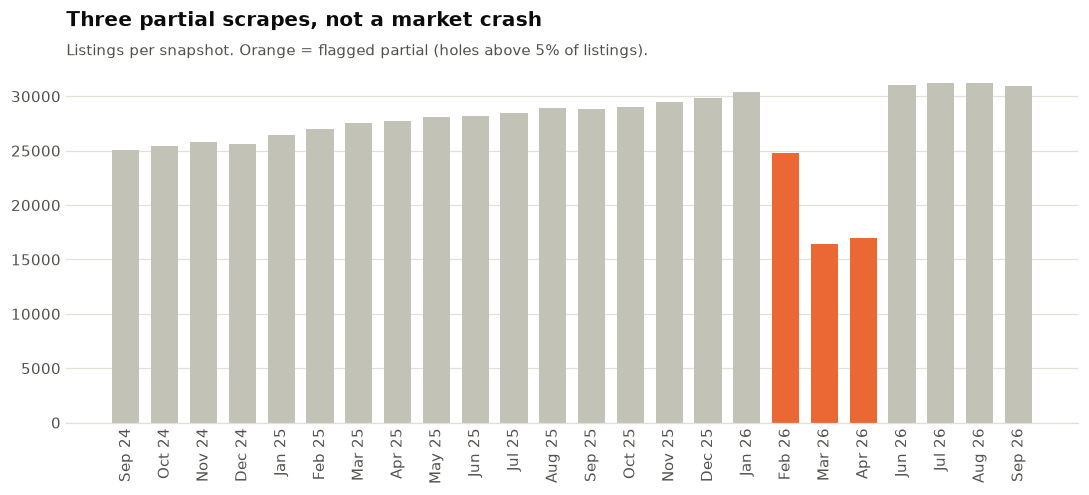

In [17]:
s = q("select * from snapshots order by snapshot_date")
fig, ax = plt.subplots()
ax.bar(s.snapshot_date.dt.strftime("%b %y"), s.listings, width=0.7, color=[GREY if c else ORANGE for c in s.is_complete])
titled(ax, "Three partial scrapes, not a market crash", "Listings per snapshot. Orange = flagged partial (holes above 5% of listings).")
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [18]:
q("select * from dq_dormant_listings")

,snapshot_date,is_complete,listings,dormant,pct_dormant
0,2024-09-25,True,25079,2810,11.2
1,2024-10-24,True,25394,2879,11.3
2,2024-11-28,True,25777,2879,11.2
3,2024-12-25,True,25609,2784,10.9
4,2025-01-29,True,26447,2774,10.5
5,2025-02-20,True,27012,2740,10.1
6,2025-03-19,True,27548,2776,10.1
7,2025-04-25,True,27726,2966,10.7
8,2025-05-26,True,28074,2724,9.7
9,2025-06-24,True,28196,2712,9.6


In [19]:
q("select * from dq_dropouts where snapshot_date >= '2025-12-01'")

,snapshot_date,is_complete,dropped_out,came_back_later,pct_came_back
0,2025-12-28,True,1065,297,27.9
1,2026-01-25,True,899,273,30.4
2,2026-02-26,False,7040,3681,52.3
3,2026-03-30,False,10271,8973,87.4
4,2026-04-27,False,1754,1339,76.3
5,2026-06-29,True,812,68,8.4
6,2026-07-23,True,643,108,16.8
7,2026-08-30,True,1231,46,3.7
8,2026-09-22,True,1185,0,0.0


In [20]:
q("select * from dq_leavers_blocked")

,snapshot_date,is_complete,last_seen_here,pct_fully_blocked
0,2024-09-25,True,701,4.3
1,2024-10-24,True,909,5.6
2,2024-11-28,True,1037,14.7
3,2024-12-25,True,773,8.5
4,2025-01-29,True,394,6.3
5,2025-02-20,True,737,6.9
6,2025-03-19,True,966,6.5
7,2025-04-25,True,711,8.3
8,2025-05-26,True,817,4.5
9,2025-06-24,True,873,4.1


In [21]:
q("select * from dq_fill_rates")

,snapshot_date,listings,pct_price,pct_bedrooms,pct_bathrooms,pct_rating,pct_iab_occupancy,pct_host_since
0,2024-09-25,25079,80.4,94.8,99.7,64.4,0.0,100.0
1,2024-10-24,25394,78.4,94.7,99.7,64.2,0.0,100.0
2,2024-11-28,25777,81.0,94.9,99.7,64.3,0.0,100.0
3,2024-12-25,25609,80.0,95.4,99.7,65.6,0.0,100.0
4,2025-01-29,26447,81.7,95.7,99.8,66.6,100.0,100.0
5,2025-02-20,27012,79.5,95.5,99.7,66.8,100.0,100.0
6,2025-03-19,27548,80.4,95.3,99.7,65.6,100.0,100.0
7,2025-04-25,27726,78.7,95.3,99.7,65.6,100.0,100.0
8,2025-05-26,28074,80.4,95.4,99.7,64.8,100.0,99.9
9,2025-06-24,28196,80.4,95.7,99.7,65.2,100.0,96.6


In [22]:
q("select * from dq_logic_checks")

,check_name,rows_failing
0,duplicate listing_id within a snapshot,0
1,last_review before first_review,0
2,reviews_ltm greater than reviews_total,0
3,min_nights greater than max_nights,0
4,last_review after the snapshot date,2893
5,last_review more than 14 days after the snapsh...,0
6,first_review before host_since,421
7,coordinates outside greater Bangkok box,0
8,"price outside 200 to 100,000 THB",955


In [23]:
q("select * from dq_quote_window")

,quote_vs_min_stay,listings,pct
0,quote length = min_nights,27046,94.4
1,quote longer than min_nights,1617,5.6


## 3. Occupancy

Inside Airbnb's San Francisco model: reviews in the last 12 months / 0.5 review rate x max(3, min_nights), capped at 255 nights.
I wrote it from scratch first and then compared it to the `estimated_occupancy_l365d` column they publish.

In [24]:
run("""
-- 03_occupancy.sql
-- Airbnb doesn't publish bookings, so occupancy has to be estimated.
--
-- Method: Inside Airbnb's "San Francisco model".
--   bookings in last 12m  = reviews in last 12m / 0.5   (assume half of guests leave a review)
--   nights per booking    = 3, or min_nights if that's higher
--   nights booked         = bookings * nights per booking, capped at 255 (70% of the year)
--
-- I rebuilt it from scratch first and then checked it against the
-- estimated_occupancy_l365d column Inside Airbnb started publishing in 2025.
-- They match exactly (occ_model_check), so the logic below is the real thing.
--
-- It's a rough model. The 50% review rate is a guess, and the calendar can't
-- tell a booked night from a night the host blocked. Treat it as a ranking
-- tool (which areas / listings do better) more than an absolute number.
--
-- est_revenue is null when there's no usable price: 678 active listings (4%)
-- in Sep 2026. Revenue totals and shares leave them out.
--
-- stay_type matters a lot later. The model multiplies reviews by min_nights,
-- and from 2026 the price is a quote for a min_nights stay, so a 7-night
-- minimum listing shows a weekly per-night rate AND gets more modelled nights
-- per review. Pricing in 04 uses 'nightly' (1-6 night minimum) when it means
-- short stays.


create or replace table listing_occupancy as
select
    listing_id,
    host_id,
    district,
    room_type,
    bedrooms,
    min_nights,
    price,
    price_ok,
    rating,
    is_superhost,
    reviews_ltm,
    reviews_ltm > 0                                               as is_active,
    min_nights < 30                                               as takes_short_stays,
    case
        when min_nights <= 6  then 'nightly'
        when min_nights <= 29 then 'weekly'
        else 'monthly'
    end                                                           as stay_type,
    least(reviews_ltm * 2 * greatest(min_nights, 3), 255)         as est_nights,
    iab_occ_nights,
    round(least(reviews_ltm * 2 * greatest(min_nights, 3), 255) / 365.0, 3) as est_occupancy,
    case when price_ok
         then least(reviews_ltm * 2 * greatest(min_nights, 3), 255) * price
    end                                                           as est_revenue
from latest;
""")

In [25]:
run("""
-- 1. Does my version reproduce theirs?
create or replace view occ_model_check as
select
    count(*)                                                    as listings,
    count(*) filter (where est_nights = iab_occ_nights)         as exact_match,
    round(100.0 * count(*) filter (where est_nights = iab_occ_nights) / count(*), 2) as pct_match,
    round(corr(est_nights, iab_occ_nights), 4)                  as correlation
from listing_occupancy;
""")

In [26]:
run("""
-- 2. Headline numbers for active listings (at least one review in the last 12 months),
-- by room type plus a city total row. grouping sets does both in one pass.
create or replace view occ_summary as
select
    coalesce(room_type, 'All active listings')                  as room_type,
    count(*)                                                    as active_listings,
    round(median(est_occupancy) * 100, 1)                       as median_occ_pct,
    round(avg(est_occupancy) * 100, 1)                          as avg_occ_pct,
    round(100.0 * count(*) filter (where est_occupancy >= 0.5) / count(*), 1) as pct_above_50,
    round(median(est_revenue))                                  as median_revenue_thb,
    round(sum(est_revenue) / 1e6, 1)                            as total_revenue_m_thb
from listing_occupancy
where is_active
group by grouping sets ((room_type), ())
order by active_listings desc;
""")

In [27]:
run("""
-- 3. Distribution. Most active listings are barely booked, a small group is near the cap.
create or replace view occ_distribution as
select
    case
        when est_nights >= 255    then '70% (capped)'
        when est_occupancy < 0.05 then '0-5%'
        when est_occupancy < 0.10 then '5-10%'
        when est_occupancy < 0.20 then '10-20%'
        when est_occupancy < 0.30 then '20-30%'
        when est_occupancy < 0.50 then '30-50%'
        else '50-70%'
    end                                                         as occupancy_band,
    count(*)                                                    as listings,
    round(100.0 * count(*) / sum(count(*)) over (), 1)          as pct_of_active,
    round(sum(est_revenue) / 1e6, 1)                            as revenue_m_thb,
    round(100.0 * sum(est_revenue) / sum(sum(est_revenue)) over (), 1) as pct_of_revenue
from listing_occupancy
where is_active
group by 1
order by min(est_occupancy);
""")

In [28]:
run("""
-- 4. By district. Districts with fewer than 30 active listings are kept but not ranked.
create or replace view occ_by_district as
with d as (
    select
        district,
        count(*)                                                as active_listings,
        median(est_occupancy)                                   as median_occ,
        percentile_cont(0.75) within group (order by est_occupancy) as p75_occ,
        avg(case when est_occupancy >= 0.5 then 1.0 else 0 end) as share_above_50,
        median(est_revenue)                                     as median_revenue,
        sum(est_revenue)                                        as total_revenue
    from listing_occupancy
    where is_active
    group by district
)
select
    district,
    active_listings,
    round(median_occ * 100, 1)                                  as median_occ_pct,
    round(p75_occ * 100, 1)                                     as p75_occ_pct,
    round(share_above_50 * 100, 1)                              as pct_above_50,
    round(median_revenue)                                       as median_revenue_thb,
    round(total_revenue / 1e6, 1)                               as total_revenue_m_thb,
    round(100.0 * total_revenue / sum(total_revenue) over (), 1) as pct_of_city_revenue,
    case when active_listings >= 30
         then rank() over (partition by active_listings >= 30 order by median_revenue desc)
    end                                                         as revenue_rank
from d
order by total_revenue desc;
""")

In [29]:
run("""
-- 4b. Entire homes by minimum stay. Longer minimums look far busier, but the
-- reviews per listing say otherwise: most of the gap is the model multiplying
-- each review by the minimum stay.
create or replace view occ_by_stay_type as
select
    stay_type,
    count(*)                                                    as active_listings,
    round(median(est_occupancy) * 100, 1)                       as median_occ_pct,
    round(avg(reviews_ltm), 1)                                  as reviews_per_listing
from listing_occupancy
where is_active
  and room_type = 'Entire home/apt'
group by stay_type
order by min(min_nights);
""")

In [30]:
run("""
-- 5. How concentrated is the money? Listings split into 10 equal groups by revenue.
create or replace view occ_revenue_deciles as
with ranked as (
    select est_revenue, ntile(10) over (order by est_revenue desc) as decile
    from listing_occupancy
    where is_active and est_revenue is not null
)
select
    decile,
    count(*)                                                    as listings,
    round(min(est_revenue))                                     as min_revenue_thb,
    round(max(est_revenue))                                     as max_revenue_thb,
    round(100.0 * sum(est_revenue) / sum(sum(est_revenue)) over (), 1) as pct_of_revenue,
    round(100.0 * sum(sum(est_revenue)) over (order by decile)
          / sum(sum(est_revenue)) over (), 1)                   as cumulative_pct
from ranked
group by decile
order by decile;
""")

In [31]:
run("""
-- 6. Forward view from the calendar: what share of nights are already
-- unavailable for each month ahead? Unavailable = booked OR blocked, so this is
-- an upper bound. Only listings that are live: reviewed in the last year and not
-- blocked for the entire next 365 days.
-- Read only the first 4-5 months. After that the number climbs again, and that's
-- not demand: lots of hosts only open their calendar 3 to 6 months out, so far
-- dates show as unavailable by default.
create or replace view occ_calendar_ahead as
with live as (
    select c.listing_id
    from stg_calendar c
    join listing_occupancy o on o.listing_id = c.listing_id
    where o.is_active
    group by c.listing_id
    having bool_or(c.is_available)
)
select
    date_trunc('month', c.cal_date)                             as month,
    count(distinct c.listing_id)                                as listings,
    round(100.0 * avg(case when c.is_available then 0 else 1 end), 1) as pct_nights_unavailable
from stg_calendar c
join live l on l.listing_id = c.listing_id
where c.cal_date >= date '2026-10-01'
  and c.cal_date <  date '2027-09-01'
group by 1
order by 1;
""")

In [32]:
run("""
-- 7. Same forward view for the high season (Nov 2026 to Feb 2027) by district,
-- next to the review-based estimate. If both point the same way I trust the ranking more.
create or replace view occ_high_season_by_district as
with live as (
    select c.listing_id
    from stg_calendar c
    join listing_occupancy o on o.listing_id = c.listing_id
    where o.is_active
    group by c.listing_id
    having bool_or(c.is_available)
),
ahead as (
    select
        o.district,
        count(distinct c.listing_id)                            as live_listings,
        avg(case when c.is_available then 0 else 1 end)        as share_unavailable
    from stg_calendar c
    join live l on l.listing_id = c.listing_id
    join listing_occupancy o on o.listing_id = c.listing_id
    where c.cal_date between date '2026-11-01' and date '2027-02-28'
    group by o.district
)
select
    a.district,
    a.live_listings,
    round(a.share_unavailable * 100, 1)                         as pct_unavailable_nov_feb,
    d.median_occ_pct                                            as review_model_median_occ_pct,
    rank() over (order by a.share_unavailable desc)             as calendar_rank
from ahead a
join occ_by_district d on d.district = a.district
where a.live_listings >= 30
order by a.share_unavailable desc;
""")

In [33]:
run("""
-- 8. One number for "do the two methods agree": Spearman rank correlation
-- (correlation of the ranks) across districts. Several districts tie on the
-- model median (it moves in steps of 1 review), so ties get the average of
-- the ranks they span: rank + (ties - 1) / 2.
create or replace view occ_method_agreement as
with r as (
    select
        rank() over (order by pct_unavailable_nov_feb desc)
          + (count(*) over (partition by pct_unavailable_nov_feb) - 1) / 2.0     as calendar_rank,
        rank() over (order by review_model_median_occ_pct desc)
          + (count(*) over (partition by review_model_median_occ_pct) - 1) / 2.0 as model_rank
    from occ_high_season_by_district
)
select
    count(*)                                                    as districts,
    round(corr(calendar_rank, model_rank), 2)                   as spearman_rho
from r;
""")

In [34]:
q("select * from occ_model_check")

,listings,exact_match,pct_match,correlation
0,30922,30922,100.0,1.0


In [35]:
q("select * from occ_summary")

,room_type,active_listings,median_occ_pct,avg_occ_pct,pct_above_50,median_revenue_thb,total_revenue_m_thb
0,All active listings,16373,18.1,26.5,18.8,111888.0,3225.3
1,Entire home/apt,12303,23.0,29.4,21.8,147570.0,2873.9
2,Private room,3806,9.9,18.3,10.4,41700.0,341.4
3,Shared room,166,3.3,8.9,2.4,5975.0,2.2
4,Hotel room,98,6.6,14.3,7.1,36972.0,7.8


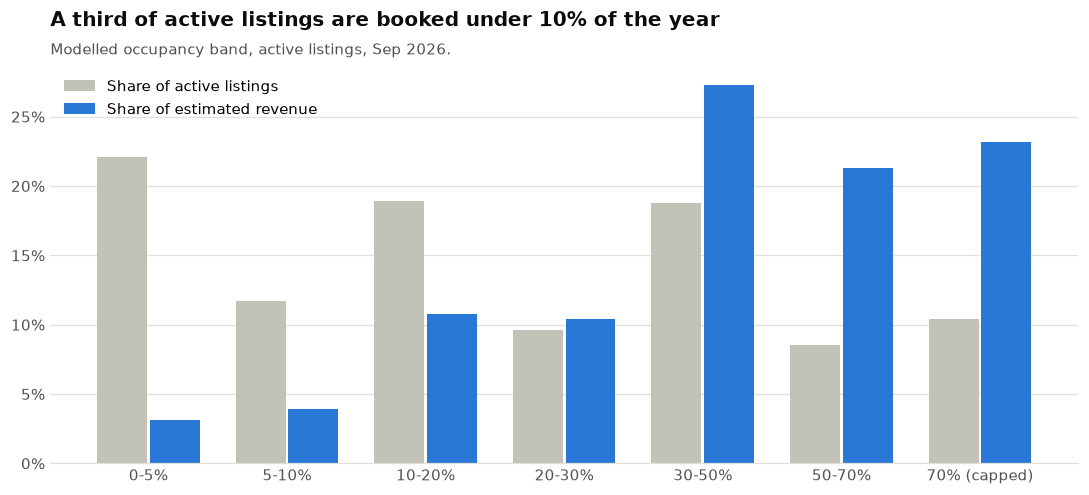

In [36]:
d = q("select * from occ_distribution")
fig, ax = plt.subplots()
x = range(len(d))
ax.bar([i - 0.19 for i in x], d.pct_of_active, width=0.36, color=GREY, label="Share of active listings")
ax.bar([i + 0.19 for i in x], d.pct_of_revenue, width=0.36, color=BLUE, label="Share of estimated revenue")
ax.set_xticks(list(x)); ax.set_xticklabels(d.occupancy_band)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.grid(axis="x", visible=False)
titled(ax, "A third of active listings are booked under 10% of the year",
       "Modelled occupancy band, active listings, Sep 2026.")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

In [37]:
q("select * from occ_revenue_deciles")

,decile,listings,min_revenue_thb,max_revenue_thb,pct_of_revenue,cumulative_pct
0,1,1570,472680.0,14745444.0,42.2,42.2
1,2,1570,308552.0,472339.0,18.5,60.7
2,3,1570,221400.0,308530.0,12.8,73.5
3,4,1570,161072.0,221340.0,9.3,82.7
4,5,1570,111800.0,161064.0,6.5,89.3
5,6,1569,74400.0,111640.0,4.5,93.8
6,7,1569,47568.0,74386.0,3.0,96.7
7,8,1569,28500.0,47562.0,1.8,98.6
8,9,1569,13872.0,28500.0,1.0,99.6
9,10,1569,1350.0,13860.0,0.4,100.0


In [38]:
q("select * from occ_by_district limit 15")

,district,active_listings,median_occ_pct,p75_occ_pct,pct_above_50,median_revenue_thb,total_revenue_m_thb,pct_of_city_revenue,revenue_rank
0,Vadhana,2874,19.7,42.7,18.9,170268.0,794.3,24.6,3
1,Khlong Toei,2415,23.0,49.3,23.2,160298.0,573.1,17.8,5
2,Huai Khwang,1586,16.4,37.0,16.1,87037.0,234.1,7.3,15
3,Ratchathewi,1007,23.0,49.3,22.3,163757.0,218.5,6.8,4
4,Bang Rak,685,23.0,51.0,25.4,183876.0,193.0,6.0,2
5,Parthum Wan,413,29.6,49.3,23.2,218592.0,151.6,4.7,1
6,Sathon,772,18.1,38.4,16.5,99833.0,142.0,4.4,10
7,Phra Khanong,733,16.4,44.4,19.2,98880.0,119.0,3.7,11
8,Khlong San,473,28.5,47.7,22.2,124430.0,85.1,2.6,7
9,Phra Nakhon,554,11.5,37.8,16.8,45338.0,79.6,2.5,32


In [39]:
q("select * from occ_by_stay_type")

,stay_type,active_listings,median_occ_pct,reviews_per_listing
0,nightly,7873,16.4,16.0
1,weekly,2939,31.2,4.2
2,monthly,1491,49.3,4.1


In [40]:
q("select * from occ_calendar_ahead")

,month,listings,pct_nights_unavailable
0,2026-10-01,16088,34.5
1,2026-11-01,16088,27.1
2,2026-12-01,16088,28.2
3,2027-01-01,16088,24.7
4,2027-02-01,16088,19.9
5,2027-03-01,16088,18.1
6,2027-04-01,16088,23.3
7,2027-05-01,16088,22.0
8,2027-06-01,16088,25.9
9,2027-07-01,16088,36.3


In [41]:
q("select * from occ_method_agreement")

,districts,spearman_rho
0,38,0.61


## 4. Pricing by area

Latest snapshot. Active entire homes (reviewed in the last 12 months) with a 1-6 night minimum ("nightly") unless a query says otherwise, the same base as the occupancy figures. The nightly vs monthly and amenity views price every listing, active or not.
Weekly and monthly listings are split out because their quoted per-night price is a discounted weekly or monthly rate.

In [42]:
run("""
-- 04_pricing_by_area.sql
-- Prices from the latest snapshot (Sep 2026, 'quote' basis).
--
-- Two things I control for everywhere here:
--   1. stay length. The quote is for a stay of min_nights, so a 7-night
--      minimum shows a weekly per-night rate and a 30-night minimum a monthly
--      one, both discounted. First version split at 30 nights and that mixed
--      weekly lets into "short stays": they're 26% of active entire homes taking
--      stays under 30 nights (price_city_overview), cheaper per night and with
--      inflated modelled occupancy. So prices here use
--      stay_type = 'nightly' (1-6 night minimum) unless a view says otherwise.
--   2. size. A district full of 2-bedroom units isn't "more expensive" than one
--      full of studios in any useful sense. Where it matters I compare like with like.
--
-- District prices (city overview, by district, by size, price bands, quadrants)
-- use active listings only (at least one review in the last 12 months), the same
-- base as the occupancy figures, so a district's price and occupancy describe the
-- same listings. Two views price every listing, active or not, and say why:
-- price_short_vs_monthly and price_amenity_premium.
-- Bad prices (price_ok = false) are excluded throughout.
""")

In [43]:
run("""
-- 1. City overview by room type and stay type
create or replace view price_city_overview as
select
    room_type,
    stay_type,
    count(*)                                                        as listings,
    percentile_cont(0.25) within group (order by price)             as p25_thb,
    percentile_cont(0.50) within group (order by price)             as median_thb,
    percentile_cont(0.75) within group (order by price)             as p75_thb
from listing_occupancy
where price_ok
  and is_active
group by room_type, stay_type
having count(*) >= 50
order by room_type, min(min_nights);
""")

In [44]:
run("""
-- 2. Nightly price by district: active entire homes, 1-6 night minimum.
-- premium_vs_city = how far the district median sits from the city median.
create or replace view price_by_district as
with base as (
    select l.district, l.price, l.guests, l.bedrooms
    from latest l
    join listing_occupancy o on o.listing_id = l.listing_id
    where o.price_ok
      and o.is_active
      and o.room_type = 'Entire home/apt'
      and o.stay_type = 'nightly'
),
city as (
    select percentile_cont(0.5) within group (order by price) as city_median
    from base
),
d as (
    select
        district,
        count(*)                                                    as listings,
        percentile_cont(0.25) within group (order by price)         as p25,
        percentile_cont(0.50) within group (order by price)         as median_price,
        percentile_cont(0.75) within group (order by price)         as p75,
        percentile_cont(0.50) within group (order by price / nullif(guests, 0)) as median_per_guest,
        avg(case when bedrooms >= 2 then 1.0 else 0 end)            as share_2br_plus
    from base
    group by district
)
select
    d.district,
    d.listings,
    round(d.median_price)                                           as median_thb,
    round(d.p25)                                                    as p25_thb,
    round(d.p75)                                                    as p75_thb,
    round(d.p75 - d.p25)                                            as iqr_thb,
    round(d.median_per_guest)                                       as median_per_guest_thb,
    round(100 * d.share_2br_plus, 1)                                as pct_2br_plus,
    round(100 * (d.median_price / c.city_median - 1), 1)            as premium_vs_city_pct,
    case when d.listings >= 30
         then rank() over (partition by d.listings >= 30 order by d.median_price desc)
    end                                                             as price_rank
from d
cross join city c
order by d.listings desc, d.district;
""")

In [45]:
run("""
-- 3. Same thing split by size, for the districts with enough supply.
-- Conditional aggregation = a pivot without a pivot function, works anywhere.
create or replace view price_district_by_size as
select
    district,
    count(*)                                                                        as listings,
    round(percentile_cont(0.5) within group (order by price) filter (where bedrooms = 0))  as studio_thb,
    round(percentile_cont(0.5) within group (order by price) filter (where bedrooms = 1))  as one_bed_thb,
    round(percentile_cont(0.5) within group (order by price) filter (where bedrooms = 2))  as two_bed_thb,
    round(percentile_cont(0.5) within group (order by price) filter (where bedrooms >= 3)) as three_plus_thb,
    count(*) filter (where bedrooms = 1)                                            as one_bed_listings
from listing_occupancy
where price_ok
  and is_active
  and room_type = 'Entire home/apt'
  and stay_type = 'nightly'
group by district
having count(*) >= 100
order by one_bed_thb desc;
""")

In [46]:
run("""
-- 4. Nightly vs monthly, 1-bedroom entire units, by district.
-- The question an owner actually asks: is Airbnb-style short letting worth it
-- over just renting the unit by the month?
--   break_even_occ = monthly per-night price / nightly price
--                    i.e. the occupancy a nightly let needs to match a unit
--                    let by the month all year
-- Ignores cleaning, platform fees, utilities and the legal side (see 07),
-- which all push the real break-even higher. It also assumes the monthly unit
-- is never empty, which is generous to monthly.
-- pct_beating_monthly is per listing, with its own price: does its estimated
-- yearly revenue beat a year of the district's median monthly rent? Comparing
-- occupancy with the district break-even instead would ignore that a listing
-- priced above the median needs fewer nights.
-- The model caps occupancy at 70%, so read this as a floor.
-- Prices here are medians of every priced 1-bed, active or not: monthly lets get
-- about 4 reviews a year, so an active-only filter would drop much of the monthly
-- side. Occupancy and pct_beating_monthly use active listings.
create or replace view price_short_vs_monthly as
with one_bed as (
    select district, stay_type, is_active, price, est_occupancy, est_revenue
    from listing_occupancy
    where price_ok
      and room_type = 'Entire home/apt'
      and bedrooms = 1
      and stay_type in ('nightly', 'monthly')
),
d as (
    select
        district,
        count(*) filter (where stay_type = 'nightly')                                       as nightly_listings,
        count(*) filter (where stay_type = 'monthly')                                       as monthly_listings,
        percentile_cont(0.5) within group (order by price) filter (where stay_type = 'nightly') as nightly_price,
        percentile_cont(0.5) within group (order by price) filter (where stay_type = 'monthly') as monthly_price
    from one_bed
    group by district
),
perf as (
    select
        o.district,
        count(*)                                                    as active_nightly,
        median(o.est_occupancy)                                     as median_occ,
        percentile_cont(0.75) within group (order by o.est_occupancy) as p75_occ,
        avg(case when o.est_revenue >= d.monthly_price * 365 then 1.0 else 0 end) as share_beating
    from one_bed o
    join d on d.district = o.district
    where o.stay_type = 'nightly' and o.is_active
    group by o.district
)
select
    d.district,
    d.nightly_listings,
    d.monthly_listings,
    round(d.nightly_price)                                          as nightly_price_thb,
    round(d.monthly_price * 30)                                     as monthly_rent_thb,
    round(100 * (1 - d.monthly_price / d.nightly_price), 2)         as monthly_discount_pct,
    round(100 * d.monthly_price / d.nightly_price, 2)               as break_even_occ_pct,
    round(100 * p.median_occ, 1)                                    as nightly_median_occ_pct,
    round(100 * p.p75_occ, 1)                                       as nightly_p75_occ_pct,
    round(100 * p.share_beating, 1)                                 as pct_beating_monthly
from d
join perf p on p.district = d.district
where d.nightly_listings >= 30 and d.monthly_listings >= 30
order by d.nightly_listings desc;
""")

In [47]:
run("""
-- 5. What's an amenity worth?
-- Naive comparison (all listings with a pool vs without) mixes in location,
-- size and property type: 76% of entire-home 1-beds taking stays under 30
-- nights list a pool (shared, in a condo tower), while the expensive end of the market is houses and townhouses that
-- mostly don't. So compare inside cells instead, two ways:
--   A: same district + bedrooms
--   B: same district + bedrooms + property type
-- In each cell take median with / median without, then average the log ratios
-- weighted by the smaller group. grouping sets builds both cell levels in one
-- pass; grouping(property_type) = 1 marks the rows where it was rolled up (A).
-- The answer moves a lot with the controls. A pool in Bangkok mostly means a
-- newer condo tower, so I read this as a building premium more than a pool one.
create or replace view price_amenity_premium as
with base as (
    select l.district, l.bedrooms, l.property_type, l.price,
           l.has_pool, l.has_gym, l.has_workspace, l.has_self_checkin
    from latest l
    join listing_occupancy o on o.listing_id = l.listing_id
    where o.price_ok
      and o.room_type = 'Entire home/apt'
      and o.stay_type = 'nightly'
      and l.bedrooms between 0 and 3
),
long as (
    select district, bedrooms, property_type, price, 'pool'      as amenity, has_pool         as has_it from base
    union all
    select district, bedrooms, property_type, price, 'gym',                  has_gym                    from base
    union all
    select district, bedrooms, property_type, price, 'workspace',            has_workspace              from base
    union all
    select district, bedrooms, property_type, price, 'self check-in',        has_self_checkin           from base
),
naive as (
    select
        amenity,
        round(100.0 * avg(case when has_it then 1 else 0 end), 1)  as pct_of_listings,
        percentile_cont(0.5) within group (order by price) filter (where has_it)
          / percentile_cont(0.5) within group (order by price) filter (where not has_it) as naive_ratio
    from long
    group by amenity
),
cells as (
    select
        amenity,
        case when grouping(property_type) = 1 then 'A' else 'B' end as level,
        count(*) filter (where has_it)                              as n_with,
        count(*) filter (where not has_it)                          as n_without,
        percentile_cont(0.5) within group (order by price) filter (where has_it)     as med_with,
        percentile_cont(0.5) within group (order by price) filter (where not has_it) as med_without
    from long
    group by grouping sets ((amenity, district, bedrooms), (amenity, district, bedrooms, property_type))
    having count(*) filter (where has_it) >= 10
       and count(*) filter (where not has_it) >= 10
),
controlled as (
    select
        amenity,
        level,
        count(*)                                                    as cells_used,
        exp(sum(least(n_with, n_without) * ln(med_with / med_without))
            / sum(least(n_with, n_without)))                        as ratio
    from cells
    group by amenity, level
)
select
    n.amenity,
    n.pct_of_listings,
    round(100 * (n.naive_ratio - 1), 1)                             as naive_premium_pct,
    round(100 * (max(c.ratio) filter (where c.level = 'A') - 1), 1) as premium_same_district_size_pct,
    round(100 * (max(c.ratio) filter (where c.level = 'B') - 1), 1) as premium_plus_property_type_pct,
    max(c.cells_used) filter (where c.level = 'B')                  as cells_used_b
from naive n
join controlled c on c.amenity = n.amenity
group by n.amenity, n.pct_of_listings, n.naive_ratio
order by premium_plus_property_type_pct desc;
""")

In [48]:
run("""
-- 6. Price bands vs guest rating and occupancy (entire homes, nightly, active).
create or replace view price_bands_vs_performance as
with base as (
    select
        price, rating, est_occupancy, est_revenue,
        ntile(10) over (order by price)                             as price_decile
    from listing_occupancy
    where price_ok and is_active
      and room_type = 'Entire home/apt'
      and stay_type = 'nightly'
)
select
    price_decile,
    count(*)                                                        as listings,
    round(min(price))                                               as from_thb,
    round(max(price))                                               as to_thb,
    round(median(rating), 2)                                        as median_rating,
    round(100 * median(est_occupancy), 1)                           as median_occ_pct,
    round(median(est_revenue))                                      as median_revenue_thb
from base
group by price_decile
order by price_decile;
""")

In [49]:
run("""
-- 7. District positioning: price vs occupancy against the city medians.
-- Feeds the scatter on the dashboard. Entire homes, nightly, active.
create or replace view price_district_quadrants as
with base as (
    select district, price, est_occupancy
    from listing_occupancy
    where price_ok and is_active
      and room_type = 'Entire home/apt'
      and stay_type = 'nightly'
),
d as (
    select
        district,
        count(*)                                                    as active_listings,
        percentile_cont(0.5) within group (order by price)          as median_price,
        percentile_cont(0.5) within group (order by est_occupancy)  as median_occ
    from base
    group by district
    having count(*) >= 30
),
city as (
    select
        percentile_cont(0.5) within group (order by price)          as city_price,
        percentile_cont(0.5) within group (order by est_occupancy)  as city_occ
    from base
)
select
    d.district,
    d.active_listings,
    round(d.median_price)                                           as median_price_thb,
    round(100 * (d.median_price / c.city_price - 1), 1)             as price_vs_city_pct,
    round(100 * d.median_occ, 1)                                    as median_occ_pct,
    case
        when d.median_price >= c.city_price and d.median_occ >= c.city_occ then 'high price, high occupancy'
        when d.median_price >= c.city_price                              then 'high price, low occupancy'
        when d.median_occ   >= c.city_occ                                then 'low price, high occupancy'
        else 'low price, low occupancy'
    end                                                             as quadrant
from d
cross join city c
order by d.active_listings desc, d.district;
""")

In [50]:
q("select * from price_city_overview")

,room_type,stay_type,listings,p25_thb,median_thb,p75_thb
0,Entire home/apt,nightly,7729,1508.00,2192.75,3484.00
1,Entire home/apt,weekly,2745,973.60,1342.42,1788.16
2,Entire home/apt,monthly,1276,838.50,1161.49,1567.42
3,Hotel room,nightly,97,800.00,1466.00,2176.00
4,Private room,nightly,3354,844.27,1200.00,1800.00
5,Private room,weekly,205,734.00,976.71,1420.50
6,Private room,monthly,133,697.68,838.64,1188.64
7,Shared room,nightly,154,334.00,411.00,493.75


In [51]:
q("select * from price_by_district where price_rank is not null order by price_rank")

,district,listings,median_thb,p25_thb,p75_thb,iqr_thb,median_per_guest_thb,pct_2br_plus,premium_vs_city_pct,price_rank
0,Parthum Wan,168,3695.0,2113.0,5999.0,3887.0,822.0,67.9,68.5,1
1,Pra Wet,36,3649.0,1887.0,6620.0,4733.0,625.0,86.1,66.4,2
2,Samphanthawong,89,2923.0,2092.0,3968.0,1877.0,647.0,59.6,33.3,3
3,Bang Rak,369,2800.0,1927.0,4320.0,2393.0,774.0,37.4,27.7,4
4,Phra Nakhon,114,2642.0,1892.0,3785.0,1893.0,538.0,57.0,20.5,5
5,Vadhana,1707,2586.0,1968.0,3975.0,2007.0,895.0,40.8,17.9,6
6,Ratchathewi,358,2502.0,1800.0,3682.0,1882.0,615.0,30.7,14.1,7
7,Bangkok Yai,38,2370.0,1557.0,4046.0,2488.0,574.0,55.3,8.1,8
8,Khlong Toei,1307,2228.0,1850.0,3390.0,1540.0,769.0,30.3,1.6,9
9,Bang Khen,32,2211.0,1445.0,3505.0,2060.0,464.0,75.0,0.8,10


In [52]:
q("select * from price_district_by_size")

,district,listings,studio_thb,one_bed_thb,two_bed_thb,three_plus_thb,one_bed_listings
0,Parthum Wan,168,1652.0,2824.0,3623.0,6703.0,50
1,Bang Rak,369,1541.0,2296.0,3355.0,5000.0,221
2,Ratchathewi,358,1705.0,2199.0,3403.0,4894.0,213
3,Vadhana,1707,2039.0,2100.0,3680.0,7284.0,992
4,Khlong Toei,1307,1867.0,2050.0,3610.0,6583.0,882
5,Phra Nakhon,114,1058.0,1872.0,3055.0,4500.0,46
6,Phra Khanong,339,1000.0,1700.0,2602.0,5554.0,209
7,Phaya Thai,159,1706.0,1671.0,2298.0,6040.0,63
8,Huai Khwang,911,793.0,1614.0,2946.0,4300.0,586
9,Sathon,369,750.0,1453.0,3559.0,6550.0,195


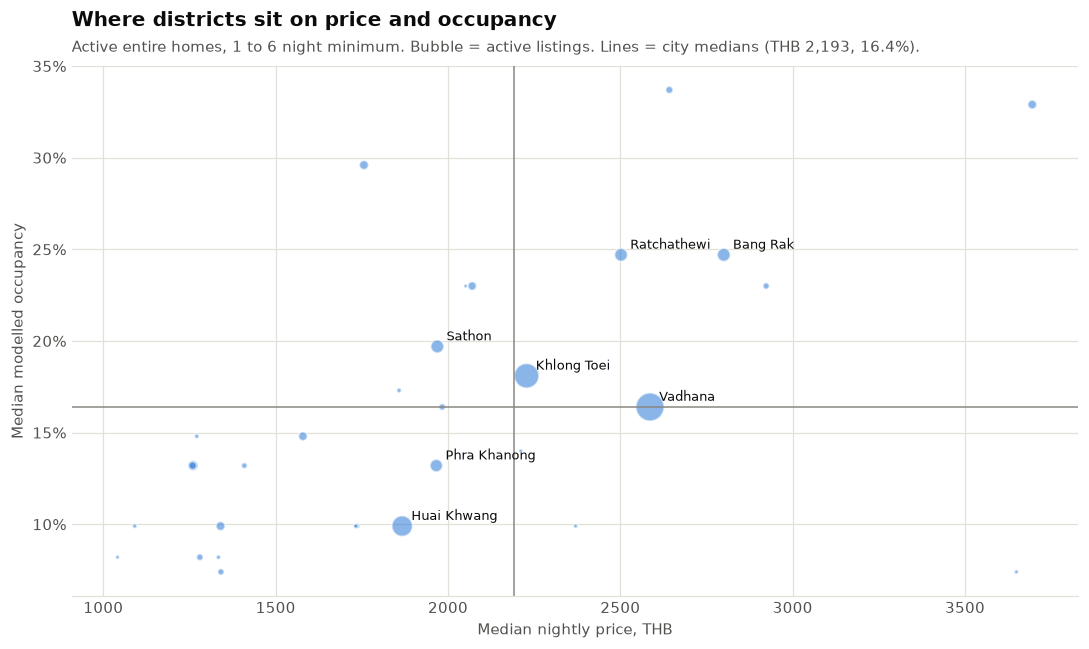

In [53]:
d = q("select * from price_district_quadrants")
city = q("""
    select percentile_cont(0.5) within group (order by price) as price,
           100 * percentile_cont(0.5) within group (order by est_occupancy) as occ
    from listing_occupancy
    where price_ok and is_active and room_type = 'Entire home/apt' and stay_type = 'nightly'
""").iloc[0]
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(d.median_price_thb, d.median_occ_pct, s=d.active_listings / 5, color=BLUE, alpha=0.55,
           edgecolor="white", linewidth=1.2)
for _, r in d[d.active_listings >= 240].iterrows():
    ax.annotate(NAMES.get(r.district, r.district), (r.median_price_thb, r.median_occ_pct), fontsize=8.5, color=INK,
                xytext=(6, 4), textcoords="offset points")
ax.axvline(city.price, color=MUTED, lw=1)
ax.axhline(city.occ, color=MUTED, lw=1)
ax.set_xlabel("Median nightly price, THB"); ax.set_ylabel("Median modelled occupancy")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
titled(ax, "Where districts sit on price and occupancy",
       f"Active entire homes, 1 to 6 night minimum. Bubble = active listings. Lines = city medians (THB {city.price:,.0f}, {city.occ:.1f}%).")
plt.tight_layout(); plt.show()

In [54]:
q("select * from price_short_vs_monthly")

,district,nightly_listings,monthly_listings,nightly_price_thb,monthly_rent_thb,monthly_discount_pct,break_even_occ_pct,nightly_median_occ_pct,nightly_p75_occ_pct,pct_beating_monthly
0,Huai Khwang,1443,316,1642.0,32988.0,33.05,66.95,8.2,23.0,5.8
1,Vadhana,1226,319,2120.0,45902.0,27.83,72.17,16.4,32.9,3.2
2,Khlong Toei,1194,281,2051.0,39469.0,35.85,64.15,18.1,40.7,11.9
3,Phra Khanong,303,82,1817.0,26951.0,50.55,49.45,13.2,27.9,10.0
4,Bang Rak,279,37,2321.0,40002.0,42.54,57.46,23.0,55.9,23.5
5,Ratchathewi,260,209,2175.0,37502.0,42.53,57.47,24.7,42.7,15.0
6,Sathon,230,92,1542.0,26274.0,43.21,56.79,18.1,33.7,6.7
7,Chatu Chak,171,39,960.0,34598.0,-20.13,120.13,11.5,21.4,0.7
8,Suanluang,159,41,1223.0,23036.0,37.23,62.77,14.8,30.0,5.0
9,Bang Na,149,76,1252.0,23692.0,36.93,63.07,11.5,27.9,4.1


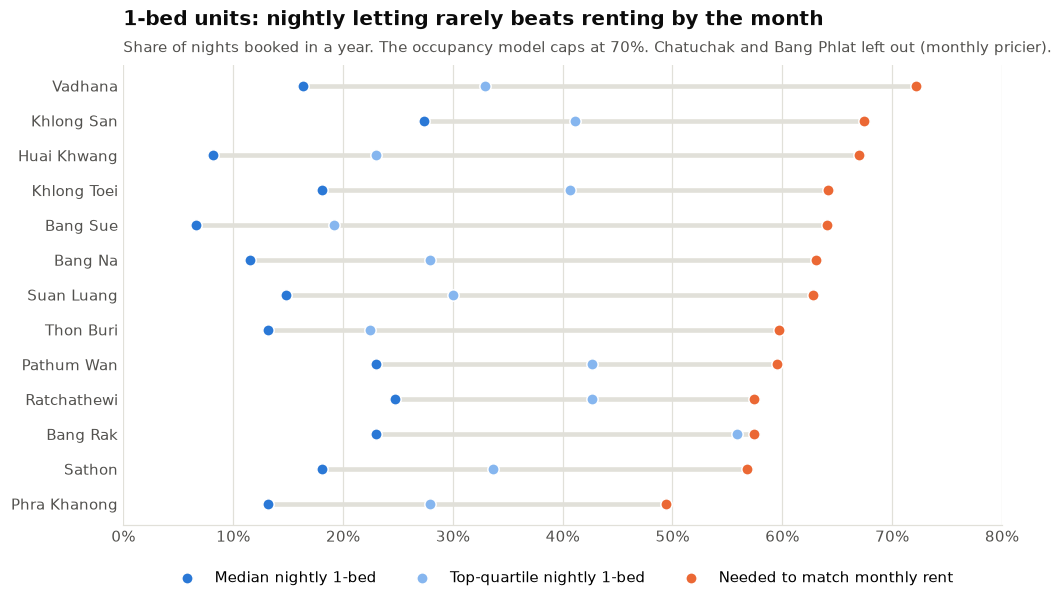

In [55]:
d = q("select * from price_short_vs_monthly where monthly_discount_pct > 0 order by break_even_occ_pct")
fig, ax = plt.subplots(figsize=(10, 5.6))
y = list(range(len(d)))
ax.hlines(y, d.nightly_median_occ_pct, d.break_even_occ_pct, color=GRID, lw=3)
ax.scatter(d.nightly_median_occ_pct, y, s=55, color=BLUE, zorder=3, edgecolor="white", label="Median nightly 1-bed")
ax.scatter(d.nightly_p75_occ_pct, y, s=55, color=BLUE_LIGHT, zorder=3, edgecolor="white", label="Top-quartile nightly 1-bed")
ax.scatter(d.break_even_occ_pct, y, s=55, color=ORANGE, zorder=3, edgecolor="white", label="Needed to match monthly rent")
ax.set_yticks(y); ax.set_yticklabels(d.district.replace(NAMES))
ax.set_xlim(0, 80)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.grid(axis="y", visible=False)
titled(ax, "1-bed units: nightly letting rarely beats renting by the month",
       "Share of nights booked in a year. The occupancy model caps at 70%. Chatuchak and Bang Phlat left out (monthly pricier).")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3); plt.tight_layout(); plt.show()

In [56]:
q("select * from price_amenity_premium")

,amenity,pct_of_listings,naive_premium_pct,premium_same_district_size_pct,premium_plus_property_type_pct,cells_used_b
0,pool,60.0,4.0,28.4,27.9,39
1,gym,42.6,5.0,8.7,8.4,45
2,workspace,69.2,4.1,3.5,3.9,48
3,self check-in,54.1,6.2,-6.6,-4.0,46


In [57]:
q("select * from price_bands_vs_performance")

,price_decile,listings,from_thb,to_thb,median_rating,median_occ_pct,median_revenue_thb
0,1,773,329.0,1043.0,4.80,13.2,36641.0
1,2,773,1044.0,1350.0,4.82,13.2,56469.0
2,3,773,1350.0,1650.0,4.83,14.8,77952.0
3,4,773,1650.0,1937.0,4.86,16.4,107198.0
4,5,773,1937.0,2193.0,4.84,19.7,147384.0
5,6,773,2193.0,2531.0,4.85,19.7,162929.0
6,7,773,2532.0,3080.0,4.85,21.4,217901.0
7,8,773,3081.0,3960.0,4.86,19.7,260103.0
8,9,773,3962.0,5740.0,4.87,18.1,318002.0
9,10,772,5750.0,71509.0,4.90,13.2,451776.0


## 5. Hosts

In [58]:
run("""
-- 05_hosts.sql
-- Who actually runs Bangkok's Airbnb supply.
-- Listing counts per host are computed here from the snapshot itself rather
-- than trusting calculated_host_listings_count, so every number lines up.
-- Host names are only shown for hosts with 20+ listings. At that size it's a
-- business. Below it, it's often someone renting out their own flat.
-- Everything here is per host account. Some companies run several accounts
-- (see host_handovers), so true operator concentration is a bit higher.


create or replace table host_latest as
select
    l.host_id,
    count(*)                                                        as listings,
    count(*) filter (where o.is_active)                             as active_listings,
    count(distinct l.district)                                      as districts,
    avg(case when l.room_type = 'Entire home/apt' then 1.0 else 0 end) as share_entire,
    bool_or(l.is_superhost)                                         as is_superhost,
    median(l.price) filter (where l.price_ok)                       as median_price,
    median(l.rating)                                                as median_rating,
    median(o.est_occupancy) filter (where o.is_active)              as median_occ,
    coalesce(sum(o.est_revenue), 0)                                 as est_revenue
from latest l
join listing_occupancy o on o.listing_id = l.listing_id
group by l.host_id;
""")

In [59]:
run("""
-- 1. Host size tiers (by total listings on the account).
-- Medians are over listings, not over hosts. A first version took the median
-- of each host's median, which made the 100+ tier look far worse (8%) than its
-- typical active listing actually is (16%).
create or replace view host_tiers as
with t as (
    select
        o.*,
        h.listings                                                  as host_size,
        case
            when h.listings = 1   then '1 listing'
            when h.listings <= 4  then '2-4'
            when h.listings <= 19 then '5-19'
            when h.listings <= 99 then '20-99'
            else '100+'
        end                                                         as tier
    from listing_occupancy o
    join host_latest h on h.host_id = o.host_id
)
select
    tier,
    count(distinct host_id)                                         as hosts,
    count(*)                                                        as listings,
    count(*) filter (where is_active)                               as active_listings,
    round(100.0 * count(*) filter (where is_active) / count(*), 1)  as pct_active,
    round(100.0 * count(*) / sum(count(*)) over (), 1)              as pct_of_listings,
    round(100.0 * count(*) filter (where is_active)
          / sum(count(*) filter (where is_active)) over (), 1)      as pct_of_active_listings,
    round(100.0 * sum(est_revenue) / sum(sum(est_revenue)) over (), 1) as pct_of_revenue,
    round(100 * median(est_occupancy) filter (where is_active), 1)  as median_occ_active_pct,
    round(median(rating), 2)                                        as median_rating,
    round(100.0 * avg(case when is_superhost then 1 else 0 end), 1) as pct_superhost_listings
from t
group by tier
order by min(host_size);
""")

In [60]:
run("""
-- 2. Top 15 hosts by listing count, with their main district
create or replace view host_top as
with district_counts as (
    select
        host_id,
        district,
        count(*)                                                    as n,
        row_number() over (partition by host_id order by count(*) desc, district) as rn
    from latest
    group by host_id, district
),
ranked as (
    select
        h.*,
        rank() over (order by h.listings desc)                      as listings_rank,
        rank() over (order by h.est_revenue desc)                   as revenue_rank
    from host_latest h
)
select
    r.listings_rank,
    r.host_id,
    case when r.listings >= 20 then hs.host_name end                as host_name,
    r.listings,
    r.active_listings,
    r.districts,
    dc.district                                                     as main_district,
    round(100 * r.share_entire, 1)                                  as pct_entire_home,
    round(r.median_price)                                           as median_price_thb,
    round(r.median_rating, 2)                                       as median_rating,
    round(100 * r.median_occ, 1)                                    as median_occ_pct,
    round(r.est_revenue / 1e6, 1)                                   as est_revenue_m_thb,
    r.revenue_rank
from ranked r
join hosts hs on hs.host_id = r.host_id
join district_counts dc on dc.host_id = r.host_id and dc.rn = 1
where r.listings_rank <= 15
order by r.listings_rank, r.host_id;
""")

In [61]:
run("""
-- 3. Concentration: how much of the market sits with the biggest hosts.
-- Gini on listings per host: 0 = everyone has the same number, 1 = one host has everything.
-- Formula with hosts sorted ascending: G = 2*sum(i*x_i) / (n*sum(x_i)) - (n+1)/n
create or replace view host_concentration as
with ranked as (
    select
        listings,
        est_revenue,
        row_number() over (order by listings desc)                  as rank_desc,
        row_number() over (order by listings asc)                   as rank_asc,
        row_number() over (order by est_revenue desc)               as revenue_rank_desc,
        count(*) over ()                                            as n_hosts
    from host_latest
)
select
    max(n_hosts)                                                    as hosts,
    sum(listings)                                                   as listings,
    round(100.0 * sum(listings) filter (where rank_desc <= 0.01 * n_hosts) / sum(listings), 1) as top_1pct_hosts_share,
    round(100.0 * sum(listings) filter (where rank_desc <= 0.10 * n_hosts) / sum(listings), 1) as top_10pct_hosts_share,
    -- revenue held by the same top 1% (by listings), then the top 1% ranked by revenue
    round(100.0 * sum(est_revenue) filter (where rank_desc <= 0.01 * n_hosts) / sum(est_revenue), 1) as top_1pct_by_listings_revenue_share,
    round(100.0 * sum(est_revenue) filter (where revenue_rank_desc <= 0.01 * n_hosts) / sum(est_revenue), 1) as top_1pct_by_revenue_revenue_share,
    round(100.0 * sum(listings) filter (where rank_desc <= 15) / sum(listings), 1) as top_15_hosts_share,
    round(2.0 * sum(rank_asc * listings) / (max(n_hosts) * sum(listings))
          - (max(n_hosts) + 1.0) / max(n_hosts), 3)                 as gini_listings
from ranked;
""")

In [62]:
run("""
-- 4. Concentration by district: HHI = sum of squared market shares (in %).
-- Thresholds from the 1992 US merger guidelines, used loosely:
-- under 1000 unconcentrated, 1000-1800 moderate, over 1800 high (1800 is still
-- the "highly concentrated" line in the 2023 guidelines).
-- Active listings only, so a host parking 100 dead listings doesn't count as
-- market share. Districts with at least 50 active listings.
create or replace view host_district_hhi as
with shares as (
    select
        district,
        host_id,
        count(*)                                                    as listings,
        100.0 * count(*) / sum(count(*)) over (partition by district) as share_pct,
        row_number() over (partition by district order by count(*) desc) as rn
    from latest
    where reviews_ltm > 0
    group by district, host_id
)
select
    s.district,
    sum(s.listings)                                                 as active_listings,
    count(*)                                                        as hosts,
    round(sum(s.share_pct * s.share_pct))                           as hhi,
    case
        when sum(s.share_pct * s.share_pct) > 1800 then 'high'
        when sum(s.share_pct * s.share_pct) >= 1000 then 'moderate'
        else 'unconcentrated'
    end                                                             as concentration,
    round(max(s.share_pct), 1)                                      as top_host_share_pct,
    round(sum(s.share_pct) filter (where s.rn <= 5), 1)             as top5_hosts_share_pct
from shares s
group by s.district
having sum(s.listings) >= 50
order by hhi desc, s.district;
""")

In [63]:
run("""
-- 5. Is the market professionalising? Share of active listings run by hosts
-- with 10+ active listings, per snapshot. Partial snapshots kept but flagged.
-- Active only, on purpose. My first version counted all listings and showed a
-- jump from 46% to 51% between Jan and Jun 2026. About half of that was the
-- scraper dropping dormant listings from Feb 2026 (see dq_dormant_listings),
-- which skew towards single-unit hosts. On active listings the share sits at
-- 41-43% for 16 months and then steps up to 44.5% across the Feb-May gap.
-- A one-off step inside a gap with partial scrapes: I can't tell from this data
-- whether it's real or another scrape change, so I don't call it a trend.
create or replace view host_pro_share_trend as
with per_host as (
    select snapshot_date, host_id, count(*) as listings
    from stg_listings
    where reviews_ltm > 0
    group by snapshot_date, host_id
)
select
    p.snapshot_date,
    s.is_complete,
    count(*)                                                        as active_hosts,
    sum(p.listings)                                                 as active_listings,
    round(sum(p.listings) * 1.0 / count(*), 2)                      as listings_per_host,
    round(100.0 * sum(p.listings) filter (where p.listings >= 10) / sum(p.listings), 1) as pct_listings_10plus_hosts,
    round(100.0 * count(*) filter (where p.listings = 1) / count(*), 1) as pct_single_listing_hosts
from per_host p
join snapshots s on s.snapshot_date = p.snapshot_date
group by p.snapshot_date, s.is_complete
order by p.snapshot_date;
""")

In [64]:
run("""
-- 6. Biggest movers between Sep 2025 and Sep 2026 (both full snapshots),
-- counting active listings. full outer join so hosts that appeared or
-- vanished are counted too.
create or replace view host_movers as
with a as (
    select host_id, count(*) as n from stg_listings
    where snapshot_date = date '2025-09-26' and reviews_ltm > 0 group by host_id
),
b as (
    select host_id, count(*) as n from stg_listings
    where snapshot_date = date '2026-09-22' and reviews_ltm > 0 group by host_id
),
j as (
    select
        coalesce(a.host_id, b.host_id)                              as host_id,
        coalesce(a.n, 0)                                            as sep_2025,
        coalesce(b.n, 0)                                            as sep_2026
    from a
    full outer join b on a.host_id = b.host_id
)
select
    j.host_id,
    case when greatest(j.sep_2025, j.sep_2026) >= 20 then h.host_name end as host_name,
    j.sep_2025,
    j.sep_2026,
    j.sep_2026 - j.sep_2025                                         as change
from j
join hosts h on h.host_id = j.host_id
where abs(j.sep_2026 - j.sep_2025) >= 25
order by change desc;


-- hosts with at least one active listing, a year apart
create or replace view host_entry_exit as
with a as (
    select distinct host_id from stg_listings
    where snapshot_date = date '2025-09-26' and reviews_ltm > 0
),
b as (
    select distinct host_id from stg_listings
    where snapshot_date = date '2026-09-22' and reviews_ltm > 0
)
select
    (select count(*) from a)                                        as hosts_sep_2025,
    (select count(*) from b)                                        as hosts_sep_2026,
    (select count(*) from a where host_id not in (select host_id from b)) as hosts_gone,
    (select count(*) from b where host_id not in (select host_id from a)) as hosts_new;
""")

In [65]:
run("""
-- 7. Listings that switch host between snapshots. Mostly management companies
-- taking over units (or one company moving units between its own accounts).
create or replace view host_handovers as
with h as (
    select
        listing_id,
        snapshot_date,
        host_id,
        lag(host_id) over (partition by listing_id order by snapshot_date) as prev_host_id
    from stg_listings
)
select
    h.host_id                                                       as new_host_id,
    case when count(*) >= 20 then hs.host_name end                  as new_host_name,
    count(*)                                                        as listings_taken_over,
    count(distinct h.prev_host_id)                                  as from_hosts,
    min(h.snapshot_date)                                            as first_seen,
    max(h.snapshot_date)                                            as last_seen
from h
join hosts hs on hs.host_id = h.host_id
where h.prev_host_id is not null
  and h.prev_host_id <> h.host_id
group by h.host_id, hs.host_name
having count(*) >= 15
order by listings_taken_over desc, new_host_id;
""")

In [66]:
run("""
-- 8. Superhost effect, compared inside district + room type cells so location
-- doesn't do the work. Weighted by the smaller group in each cell.
create or replace view host_superhost_effect as
with cells as (
    select
        district,
        room_type,
        count(*) filter (where is_superhost)                        as n_super,
        count(*) filter (where not is_superhost)                    as n_other,
        median(price) filter (where is_superhost and price_ok)      as price_super,
        median(price) filter (where not is_superhost and price_ok)  as price_other,
        median(est_occupancy) filter (where is_superhost)           as occ_super,
        median(est_occupancy) filter (where not is_superhost)       as occ_other,
        median(rating) filter (where is_superhost)                  as rating_super,
        median(rating) filter (where not is_superhost)              as rating_other
    from listing_occupancy
    where is_active
    group by district, room_type
    having count(*) filter (where is_superhost) >= 15
       and count(*) filter (where not is_superhost) >= 15
)
select
    count(*)                                                        as cells,
    sum(n_super)                                                    as superhost_listings,
    sum(n_other)                                                    as other_listings,
    round(100 * (exp(sum(least(n_super, n_other) * ln(price_super / price_other))
                     / sum(least(n_super, n_other))) - 1), 1)       as price_premium_pct,
    round(100 * sum(least(n_super, n_other) * (occ_super - occ_other))
          / sum(least(n_super, n_other)), 1)                        as occupancy_gap_pts,
    round(sum(least(n_super, n_other) * (rating_super - rating_other))
          / sum(least(n_super, n_other)), 2)                        as rating_gap
from cells;
""")

In [67]:
q("select * from host_tiers")

,tier,hosts,listings,active_listings,pct_active,pct_of_listings,pct_of_active_listings,pct_of_revenue,median_occ_active_pct,median_rating,pct_superhost_listings
0,1 listing,4503,4503,1831,40.7,14.6,11.2,12.6,21.9,4.90,20.7
1,2-4,2109,5605,3236,57.7,18.1,19.8,20.4,19.7,4.89,39.1
2,5-19,1135,9362,5485,58.6,30.3,33.5,34.4,16.4,4.86,44.8
3,20-99,225,8905,4949,55.6,28.8,30.2,27.9,18.1,4.81,36.5
4,100+,17,2547,872,34.2,8.2,5.3,4.6,16.4,4.83,32.1


In [68]:
q("select * from host_top")

,listings_rank,host_id,host_name,listings,active_listings,districts,main_district,pct_entire_home,median_price_thb,median_rating,median_occ_pct,est_revenue_m_thb,revenue_rank
0,1,262132406,None,257,46,10,Huai Khwang,89.5,1454.0,5.00,5.5,2.2,298
1,2,574804920,None,247,15,9,Khlong Toei,96.4,4845.0,5.00,3.3,3.8,166
2,3,493412920,None,231,13,26,Phra Nakhon,0.0,3539.0,4.04,1.6,0.2,2257
3,4,10005164,None,203,164,13,Vadhana,99.5,1647.0,5.00,46.0,45.7,1
4,5,201677068,None,192,80,12,Huai Khwang,99.5,1499.0,4.65,31.8,10.5,37
5,6,680424509,None,129,2,9,Huai Khwang,100.0,1540.0,2.50,9.6,0.0,3850
6,7,693626993,None,127,107,4,Huai Khwang,100.0,2380.0,5.00,8.2,19.1,9
7,8,26736483,None,122,81,5,Bang Rak,93.4,2007.0,4.51,8.2,6.8,69
8,8,52161947,None,122,62,9,Khlong Toei,99.2,1296.0,4.60,29.3,9.0,47
9,10,122824264,None,121,105,4,Vadhana,100.0,1827.0,5.00,65.8,37.2,2


In [69]:
q("select * from host_concentration")

,hosts,listings,top_1pct_hosts_share,top_10pct_hosts_share,top_1pct_by_listings_revenue_share,top_1pct_by_revenue_revenue_share,top_15_hosts_share,gini_listings
0,7989,30922.0,21.1,56.7,14.1,30.2,7.5,0.628


In [70]:
q("select * from host_district_hhi limit 10")

,district,active_listings,hosts,hhi,concentration,top_host_share_pct,top5_hosts_share_pct
0,Saphan Sung,62.0,19,2851.0,high,51.6,74.2
1,Bang Phlat,204.0,72,1089.0,moderate,30.9,47.1
2,Lak Si,83.0,38,629.0,unconcentrated,18.1,44.6
3,Bang Kho laen,116.0,54,623.0,unconcentrated,20.7,40.5
4,Bangkok Yai,85.0,40,544.0,unconcentrated,16.5,38.8
5,Bangkok Noi,82.0,46,402.0,unconcentrated,11.0,35.4
6,Bang Khen,81.0,53,380.0,unconcentrated,13.6,32.1
7,Pra Wet,109.0,58,364.0,unconcentrated,12.8,30.3
8,Don Mueang,107.0,52,338.0,unconcentrated,9.3,30.8
9,Lat Krabang,136.0,65,315.0,unconcentrated,9.6,29.4


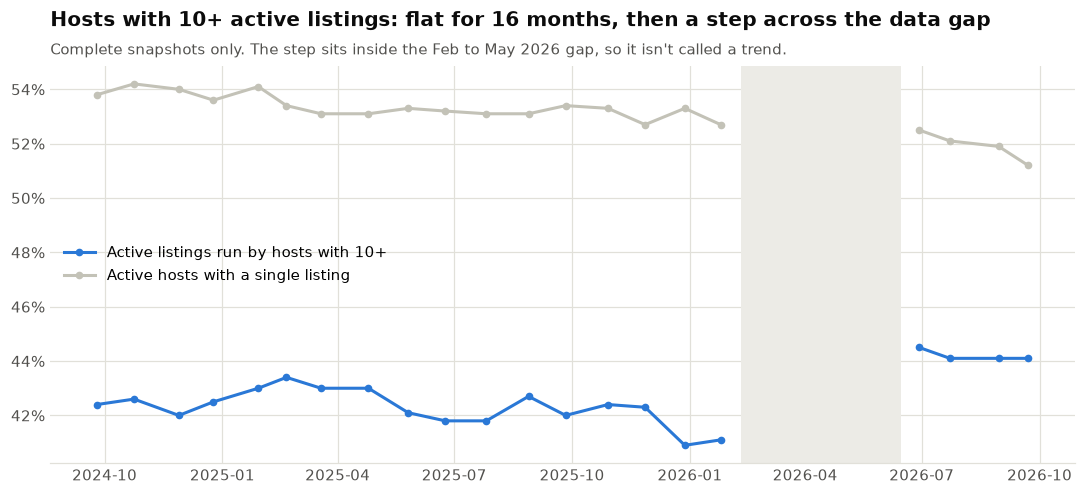

In [71]:
d = q("select * from host_pro_share_trend where is_complete")
fig, ax = plt.subplots()
# plot before and after the Feb-May 2026 gap separately so no line is drawn through it
for part in (d[d.snapshot_date < "2026-02-01"], d[d.snapshot_date > "2026-06-01"]):
    first = part.snapshot_date.min() < pd.Timestamp("2026-02-01")
    ax.plot(part.snapshot_date, part.pct_listings_10plus_hosts, color=BLUE, lw=2, marker="o", ms=4,
            label="Active listings run by hosts with 10+" if first else None)
    ax.plot(part.snapshot_date, part.pct_single_listing_hosts, color=GREY, lw=2, marker="o", ms=4,
            label="Active hosts with a single listing" if first else None)
ax.axvspan(pd.Timestamp("2026-02-10"), pd.Timestamp("2026-06-15"), color="#ecebe6", lw=0)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
titled(ax, "Hosts with 10+ active listings: flat for 16 months, then a step across the data gap",
       "Complete snapshots only. The step sits inside the Feb to May 2026 gap, so it isn't called a trend.")
ax.legend(loc="center left"); plt.tight_layout(); plt.show()

In [72]:
q("select * from host_entry_exit")

,hosts_sep_2025,hosts_sep_2026,hosts_gone,hosts_new
0,4379,4528,1034,1183


In [73]:
q("select * from host_superhost_effect")

,cells,superhost_listings,other_listings,price_premium_pct,occupancy_gap_pts,rating_gap
0,57,8453.0,7038.0,10.2,13.4,0.18


## 6. Trends

In [74]:
run("""
-- 06_trends.sql
-- Month over month. Three sources, each with its own catch:
--   reviews file   full history back to 2011, but only for listings still alive
--                  in Sep 2026, so older months are undercounted (checked below).
--   snapshots      24 monthly scrapes, Sep 2024 to Sep 2026. No May 2026, and
--                  Feb to Apr 2026 are partial. Changes and YoY are computed
--                  between complete snapshots only. Views that list every
--                  snapshot keep the partial ones as flagged rows.
--   prices         two series that can't be joined (listed price until Nov 2025,
--                  quote price from Mar 2026). Measured as same-listing changes,
--                  complete snapshots only, so the quote series starts in Jun 2026.


-- month number that works in any SQL dialect: year * 12 + month
create or replace view snapshot_months as
select
    snapshot_date,
    is_complete,
    cast(extract(year from snapshot_date) * 12 + extract(month from snapshot_date) as int) as month_no
from snapshots;
""")

In [75]:
run("""
-- 1. Reviews per month, with MoM, YoY and a 3 month rolling average.
-- A month spine first, so lag(12) really means 12 months back even if a month had zero reviews.
create or replace view trend_reviews_monthly as
with spine as (
    select cast(m as date) as month
    from generate_series(date '2016-01-01', date '2026-08-01', interval '1 month') as t(m)
),
counts as (
    select date_trunc('month', review_date) as month, count(*) as reviews
    from stg_reviews
    group by 1
),
filled as (
    select s.month, coalesce(c.reviews, 0) as reviews
    from spine s
    left join counts c on c.month = s.month
)
select
    month,
    reviews,
    round(100.0 * (reviews - lag(reviews) over w) / nullif(lag(reviews) over w, 0), 1)         as mom_pct,
    round(100.0 * (reviews - lag(reviews, 12) over w) / nullif(lag(reviews, 12) over w, 0), 1) as yoy_pct,
    round(avg(reviews) over (order by month rows between 2 preceding and current row))        as rolling_3m
from filled
window w as (order by month)
order by month;
""")

In [76]:
run("""
-- 2. Seasonality, 2023-2025. Each month divided by a centred 12 month moving
-- average (the "2x12" one: 13 months with the two ends at half weight), then
-- averaged by calendar month and scaled so the average month = 100.
-- Each month's share of its calendar year doesn't work here: with reviews
-- growing 19% to 137% a year it inflates late-year months and deflates early ones,
-- and puts the peak in December when January is higher every year.
-- Review dates trail the actual stay by a week or two.
create or replace view trend_seasonality as
with ma as (
    select
        month,
        reviews,
        (sum(reviews) over (order by month rows between 6 preceding and 6 following)
           - 0.5 * lag(reviews, 6)  over (order by month)
           - 0.5 * lead(reviews, 6) over (order by month)) / 12.0  as trend,
        count(*) over (order by month rows between 6 preceding and 6 following) as months_in_window
    from trend_reviews_monthly
),
ratios as (
    select extract(month from month) as mon, reviews / trend as ratio
    from ma
    where month >= date '2023-01-01' and month < date '2026-01-01'
      and months_in_window = 13
),
by_month as (
    select mon, avg(ratio) as avg_ratio, min(ratio) as min_ratio, max(ratio) as max_ratio
    from ratios
    group by mon
)
select
    cast(mon as int)                                                as month_of_year,
    round(100 * avg_ratio / avg(avg_ratio) over ())                 as season_index,
    round(100 * min_ratio / avg(avg_ratio) over ())                 as lowest_year,
    round(100 * max_ratio / avg(avg_ratio) over ())                 as highest_year
from by_month
order by mon;
""")

In [77]:
run("""
-- 3. How big is the survivorship gap in the reviews file?
-- Listings that dropped out before Sep 2026 take their reviews with them.
-- Their last known review count tells me how much history is missing.
create or replace view trend_review_survivorship as
with last_seen as (
    select listing_id, max(snapshot_date) as last_date
    from stg_listings
    group by listing_id
),
gone as (
    select l.listing_id, l.reviews_total, l.reviews_ltm
    from stg_listings l
    join last_seen s on s.listing_id = l.listing_id and s.last_date = l.snapshot_date
    where s.last_date < (select max(snapshot_date) from stg_listings)
)
select
    count(*)                                                        as listings_gone_since_sep_2024,
    sum(reviews_total)                                              as their_reviews,
    (select count(*) from stg_reviews)                              as reviews_in_file,
    round(100.0 * sum(reviews_total) / (sum(reviews_total) + (select count(*) from stg_reviews)), 1) as pct_of_history_missing
from gone;
""")

In [78]:
run("""
-- 3b. Same question, put as growth. Last 12 full months vs the 12 before,
-- counted two ways. The gap between them is the survivorship bias.
create or replace view trend_growth_two_ways as
select
    'reviews file (Sep-Aug windows)'                                as method,
    sum(reviews) filter (where month between date '2024-09-01' and date '2025-08-01') as prior_12m,
    sum(reviews) filter (where month between date '2025-09-01' and date '2026-08-01') as last_12m,
    round(100.0 * sum(reviews) filter (where month between date '2025-09-01' and date '2026-08-01')
          / sum(reviews) filter (where month between date '2024-09-01' and date '2025-08-01') - 100, 1) as growth_pct
from trend_reviews_monthly
union all
select
    'snapshot panel (reviews_ltm, Sep 2025 vs Sep 2026)',
    sum(reviews_ltm) filter (where snapshot_date = date '2025-09-26'),
    sum(reviews_ltm) filter (where snapshot_date = date '2026-09-22'),
    round(100.0 * sum(reviews_ltm) filter (where snapshot_date = date '2026-09-22')
          / sum(reviews_ltm) filter (where snapshot_date = date '2025-09-26') - 100, 1)
from stg_listings;
""")

In [79]:
run("""
-- 3c. Occupancy over time. Same model as 03_occupancy.sql, applied to every
-- snapshot (reviews_ltm and min_nights exist in all of them). Each point is a
-- trailing 12 month figure, so it moves slowly by design.
-- Watch out: the model multiplies reviews by min_nights, so if hosts shorten
-- their minimum stay, modelled occupancy drops even with the same bookings.
-- That's what happens in Dec 2025 (share of active listings with a 30+ night
-- minimum goes from 12% to 10%). reviews_per_active_listing doesn't have that
-- problem, which is why it's here too.
create or replace view trend_occupancy as
select
    l.snapshot_date,
    s.is_complete,
    count(*)                                                        as active_listings,
    round(sum(l.reviews_ltm) * 1.0 / count(*), 2)                   as reviews_per_active_listing,
    round(100.0 * avg(case when l.min_nights >= 30 then 1 else 0 end), 1) as pct_min_30_plus,
    round(100 * median(least(l.reviews_ltm * 2 * greatest(l.min_nights, 3), 255) / 365.0), 1) as median_occ_pct,
    round(100 * avg(least(l.reviews_ltm * 2 * greatest(l.min_nights, 3), 255) / 365.0), 1)    as avg_occ_pct,
    round(100.0 * avg(case when l.reviews_ltm * 2 * greatest(l.min_nights, 3) >= 0.5 * 365 then 1 else 0 end), 1) as pct_above_50
from stg_listings l
join snapshots s on s.snapshot_date = l.snapshot_date
where l.reviews_ltm > 0
group by l.snapshot_date, s.is_complete
order by l.snapshot_date;
""")

In [80]:
run("""
-- 3d. Minimum stay changes between back-to-back snapshots, listings active in
-- both. The Dec 2025 step in modelled occupancy lines up with a wave of hosts
-- cutting their minimum stay: 2,035 that month against 264 the month before.
create or replace view trend_min_stay_changes as
with s as (
    select snapshot_date, lag(snapshot_date) over (order by snapshot_date) as prev_date
    from snapshots
)
select
    c.snapshot_date,
    sn.is_complete,
    count(*)                                                        as active_in_both,
    count(*) filter (where c.min_nights < p.min_nights)             as cut_min_stay,
    count(*) filter (where c.min_nights > p.min_nights)             as raised_min_stay
from s
join stg_listings c on c.snapshot_date = s.snapshot_date
join stg_listings p on p.snapshot_date = s.prev_date and p.listing_id = c.listing_id
join snapshots sn on sn.snapshot_date = c.snapshot_date
where c.reviews_ltm > 0
  and p.reviews_ltm > 0
group by c.snapshot_date, sn.is_complete
order by c.snapshot_date;
""")

In [81]:
run("""
-- 4. Supply per snapshot: total, active, new, gone.
--   new  = first time this listing id appears (Sep 2024 skipped, everything is "new" there)
--   gone = seen in the previous snapshot and never again
-- change_vs_prev_complete skips partial snapshots so the Feb-Apr 2026 dip doesn't fake a crash.
-- Use the active column for anything across Feb 2026: total listings lost ~2,300
-- dormant units that month to a scraper change (dq_dormant_listings).
-- The Jun 2026 "new" number is inflated: it covers everything created since
-- January that the partial scrapes and the missing May snapshot didn't catch.
create or replace view trend_supply as
with seen as (
    select listing_id, min(snapshot_date) as first_seen, max(snapshot_date) as last_seen
    from stg_listings
    group by listing_id
),
prev as (
    select snapshot_date, lag(snapshot_date) over (order by snapshot_date) as prev_date
    from snapshots
),
per as (
    select
        l.snapshot_date,
        count(*)                                                    as listings,
        count(*) filter (where l.reviews_ltm > 0)                   as active_listings,
        count(*) filter (where s.first_seen = l.snapshot_date)      as new_listings
    from stg_listings l
    join seen s on s.listing_id = l.listing_id
    group by l.snapshot_date
),
gone as (
    select p.snapshot_date, count(*) as gone_listings
    from prev p
    join seen s on s.last_seen = p.prev_date
    group by p.snapshot_date
),
complete_only as (
    select
        per.snapshot_date,
        per.listings,
        per.active_listings,
        lag(per.listings) over (order by per.snapshot_date)         as prev_listings,
        lag(per.active_listings) over (order by per.snapshot_date)  as prev_active,
        lag(per.snapshot_date) over (order by per.snapshot_date)    as prev_complete_date
    from per
    join snapshots s on s.snapshot_date = per.snapshot_date
    where s.is_complete
)
select
    per.snapshot_date,
    s.is_complete,
    per.listings,
    per.active_listings,
    case when per.snapshot_date > date '2024-09-25' then per.new_listings end as new_listings,
    g.gone_listings,
    c.prev_complete_date,
    round(100.0 * (c.listings - c.prev_listings) / c.prev_listings, 1) as change_vs_prev_complete_pct,
    round(100.0 * (c.active_listings - c.prev_active) / c.prev_active, 1) as active_change_vs_prev_complete_pct
from per
join snapshots s on s.snapshot_date = per.snapshot_date
left join gone g on g.snapshot_date = per.snapshot_date
left join complete_only c on c.snapshot_date = per.snapshot_date
order by per.snapshot_date;
""")

In [82]:
run("""
-- 5. Same-listing price index.
-- For each pair of back-to-back priced snapshots, take listings in both, same
-- price basis, same min_nights, valid price in both. Average log change per pair
-- (a geometric mean, the Jevons index), then chain it with a running sum.
-- Comparing the same listings to themselves means new luxury units entering
-- can't push the "price" up on their own.
-- Not the median change: a third or more of listings don't touch their price,
-- so the median comes out as 0 almost every month.
-- Changes bigger than 3x either way are dropped as data noise.
create or replace view trend_price_index as
with priced as (
    select snapshot_date, row_number() over (order by snapshot_date) as seq
    from snapshots
    where priced > 0 and is_complete
),
pairs as (
    select
        cur.snapshot_date,
        prv.snapshot_date                                           as prev_date,
        c.price_basis,
        ln(c.price / p.price)                                       as log_change,
        c.price = p.price                                           as unchanged
    from priced cur
    join priced prv on prv.seq = cur.seq - 1
    join stg_listings c on c.snapshot_date = cur.snapshot_date
    join stg_listings p on p.snapshot_date = prv.snapshot_date and p.listing_id = c.listing_id
    where c.price_ok and p.price_ok
      and c.price_basis = p.price_basis
      and c.min_nights = p.min_nights
),
per_pair as (
    select
        snapshot_date,
        prev_date,
        price_basis,
        count(*)                                                    as matched_listings,
        avg(log_change)                                             as avg_log_change,
        avg(case when unchanged then 1.0 else 0 end)                as share_unchanged,
        avg(case when log_change > 0 then 1.0 else 0 end)           as share_up,
        avg(case when log_change < 0 then 1.0 else 0 end)           as share_down
    from pairs
    where abs(log_change) < ln(3)
    group by snapshot_date, prev_date, price_basis
)
select
    snapshot_date,
    prev_date,
    price_basis,
    matched_listings,
    round(100 * (exp(avg_log_change) - 1), 2)                       as avg_change_pct,
    round(100 * share_unchanged, 1)                                 as pct_unchanged,
    round(100 * share_up, 1)                                        as pct_up,
    round(100 * share_down, 1)                                      as pct_down,
    round(100 * exp(sum(avg_log_change) over (partition by price_basis order by snapshot_date)), 1) as price_index
from per_pair
union all
-- base month of each series, so the line starts at 100
select min(prev_date), null, price_basis, null, null, null, null, null, 100.0
from per_pair
group by price_basis
order by snapshot_date;
""")

In [83]:
run("""
-- 5b. Demand without the survivorship problem: every snapshot carries
-- reviews_ltm (reviews in the 12 months before the scrape) for every listing
-- live at that moment, including ones that later disappear. Summing it gives a
-- rolling 12 month review count straight from the panel.
create or replace view trend_demand_ltm as
with t as (
    select
        l.snapshot_date,
        s.is_complete,
        m.month_no,
        sum(l.reviews_ltm)                                          as reviews_last_12m,
        count(*) filter (where l.reviews_ltm > 0)                   as listings_with_reviews
    from stg_listings l
    join snapshots s on s.snapshot_date = l.snapshot_date
    join snapshot_months m on m.snapshot_date = l.snapshot_date
    group by l.snapshot_date, s.is_complete, m.month_no
)
select
    a.snapshot_date,
    a.is_complete,
    a.reviews_last_12m,
    a.listings_with_reviews,
    b.reviews_last_12m                                              as same_month_last_year,
    case when a.is_complete and b.is_complete
         then round(100.0 * (a.reviews_last_12m - b.reviews_last_12m) / b.reviews_last_12m, 1)
    end                                                             as yoy_pct
from t a
left join t b on b.month_no = a.month_no - 12
order by a.snapshot_date;
""")

In [84]:
run("""
-- 6. Which districts grew? Sep 2025 vs Sep 2026, both full snapshots.
-- Ranked on active listings because of the dormant-listing change in Feb 2026.
-- Districts with 100+ active listings a year earlier, so a few listings can't
-- swing the percentage.
create or replace view trend_district_growth as
with a as (
    select district, count(*) as n, count(*) filter (where reviews_ltm > 0) as active
    from stg_listings where snapshot_date = date '2025-09-26' group by district
),
b as (
    select district, count(*) as n, count(*) filter (where reviews_ltm > 0) as active
    from stg_listings where snapshot_date = date '2026-09-22' group by district
)
select
    b.district,
    a.active                                                        as active_sep_2025,
    b.active                                                        as active_sep_2026,
    b.active - a.active                                             as active_change,
    round(100.0 * (b.active - a.active) / a.active, 1)              as active_change_pct,
    round(100.0 * (b.n - a.n) / a.n, 1)                             as all_listings_change_pct,
    rank() over (order by 1.0 * (b.active - a.active) / a.active desc) as growth_rank
from b
join a on a.district = b.district
where a.active >= 100
order by growth_rank;
""")

In [85]:
run("""
-- 6b. Is a district's growth one operator? Listings active in Sep 2026 that
-- weren't active in Sep 2025, and how many of those sit with the biggest
-- single host. In Thon Buri one host has 36 of the 180.
create or replace view trend_district_new_listings as
with newly as (
    select l.district, l.host_id
    from stg_listings l
    where l.snapshot_date = date '2026-09-22'
      and l.reviews_ltm > 0
      and not exists (
          select 1 from stg_listings b
          where b.listing_id = l.listing_id
            and b.snapshot_date = date '2025-09-26'
            and b.reviews_ltm > 0
      )
),
by_host as (
    select district, host_id, count(*) as n
    from newly
    group by district, host_id
)
select
    g.district,
    g.active_change,
    sum(h.n)                                                        as newly_active,
    max(h.n)                                                        as top_host_newly_active,
    round(100.0 * max(h.n) / sum(h.n), 1)                           as top_host_pct
from trend_district_growth g
join by_host h on h.district = g.district
group by g.district, g.active_change, g.growth_rank
order by g.growth_rank;
""")

In [86]:
run("""
-- 7. Cohort retention. Listings grouped by the month they first appeared
-- (Oct 2024 to Sep 2025). What share is still listed 3, 6 and 12 months later?
-- Null where the target month is missing or a partial snapshot.
-- Anything measured after Feb 2026 is pulled down a bit by the dormant-listing
-- scope change, so the last column is a floor.
-- "New" means first seen in the panel. The Oct 2024 cohort includes a few
-- older listings that were just missing from Sep 2024 (9% had a first review
-- 90+ days before, vs 2.5-5.5% for later cohorts).
create or replace view trend_cohort_retention as
with first_seen as (
    select listing_id, min(snapshot_date) as cohort_date
    from stg_listings
    group by listing_id
),
cohorts as (
    select f.listing_id, f.cohort_date, m.month_no as cohort_month
    from first_seen f
    join snapshot_months m on m.snapshot_date = f.cohort_date
    where f.cohort_date between date '2024-10-01' and date '2025-09-30'
),
sizes as (
    select cohort_date, cohort_month, count(*) as cohort_size
    from cohorts
    group by cohort_date, cohort_month
),
retained as (
    -- how many of each cohort are listed N months later
    select c.cohort_date, m.month_no - c.cohort_month as months_after, count(*) as still_listed
    from cohorts c
    join stg_listings l on l.listing_id = c.listing_id
    join snapshot_months m on m.snapshot_date = l.snapshot_date
    where m.is_complete
    group by c.cohort_date, m.month_no - c.cohort_month
),
latest_month as (
    select max(month_no) as month_no from snapshot_months
)
select
    s.cohort_date,
    s.cohort_size,
    max(case when r.months_after = 3  then round(100.0 * r.still_listed / s.cohort_size, 1) end) as m3_pct,
    max(case when r.months_after = 6  then round(100.0 * r.still_listed / s.cohort_size, 1) end) as m6_pct,
    max(case when r.months_after = 12 then round(100.0 * r.still_listed / s.cohort_size, 1) end) as m12_pct,
    max(case when r.months_after = lm.month_no - s.cohort_month
             then round(100.0 * r.still_listed / s.cohort_size, 1) end)                        as still_listed_sep_2026_pct
from sizes s
cross join latest_month lm
left join retained r on r.cohort_date = s.cohort_date
group by s.cohort_date, s.cohort_size, s.cohort_month, lm.month_no
order by s.cohort_date;
""")

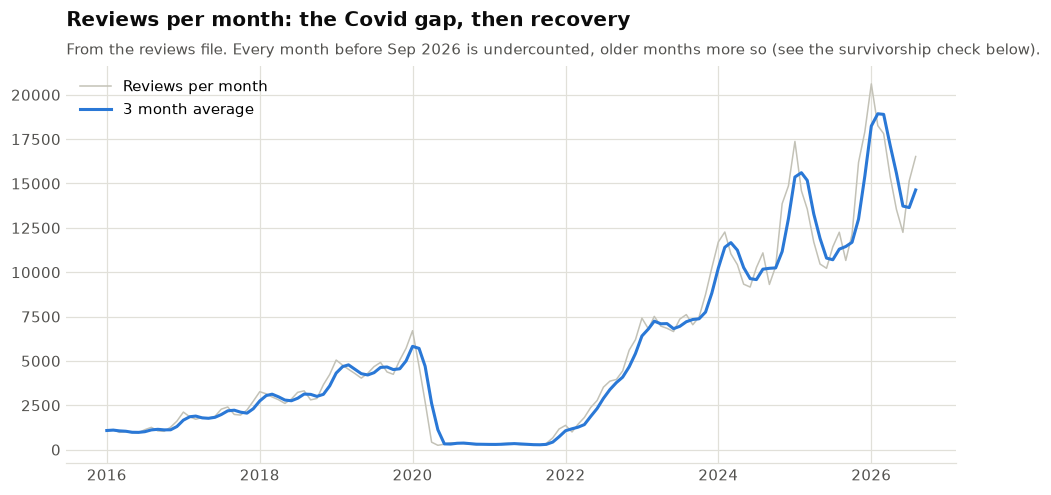

In [87]:
d = q("select * from trend_reviews_monthly")
fig, ax = plt.subplots()
ax.plot(d.month, d.reviews, color=GREY, lw=1, label="Reviews per month")
ax.plot(d.month, d.rolling_3m, color=BLUE, lw=2, label="3 month average")
titled(ax, "Reviews per month: the Covid gap, then recovery",
       "From the reviews file. Every month before Sep 2026 is undercounted, older months more so (see the survivorship check below).")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

In [88]:
q("select * from trend_seasonality")

,month_of_year,season_index,lowest_year,highest_year
0,1,129.0,123.0,141.0
1,2,117.0,108.0,126.0
2,3,111.0,108.0,114.0
3,4,99.0,92.0,102.0
4,5,89.0,81.0,96.0
5,6,84.0,78.0,90.0
6,7,90.0,86.0,95.0
7,8,93.0,90.0,95.0
8,9,79.0,76.0,83.0
9,10,85.0,85.0,86.0


In [89]:
q("select * from trend_review_survivorship")

,listings_gone_since_sep_2024,their_reviews,reviews_in_file,pct_of_history_missing
0,20661,155484.0,721646,17.7


In [90]:
q("select * from trend_growth_two_ways")

,method,prior_12m,last_12m,growth_pct
0,reviews file (Sep-Aug windows),149951.0,186436.0,24.3
1,"snapshot panel (reviews_ltm, Sep 2025 vs Sep 2...",168223.0,185922.0,10.5


In [91]:
q("select * from trend_demand_ltm")

,snapshot_date,is_complete,reviews_last_12m,listings_with_reviews,same_month_last_year,yoy_pct
0,2024-09-25,True,156451.0,13106,NaN,NaN
1,2024-10-24,True,158982.0,13224,NaN,NaN
2,2024-11-28,True,162295.0,13536,NaN,NaN
3,2024-12-25,True,165654.0,13804,NaN,NaN
4,2025-01-29,True,173157.0,14585,NaN,NaN
5,2025-02-20,True,175495.0,14869,NaN,NaN
6,2025-03-19,True,173420.0,14830,NaN,NaN
7,2025-04-25,True,172125.0,14818,NaN,NaN
8,2025-05-26,True,169529.0,14717,NaN,NaN
9,2025-06-24,True,169626.0,14826,NaN,NaN


In [92]:
q("select * from trend_occupancy")

,snapshot_date,is_complete,active_listings,reviews_per_active_listing,pct_min_30_plus,median_occ_pct,avg_occ_pct,pct_above_50
0,2024-09-25,True,13106,11.94,9.9,19.2,27.7,22.0
1,2024-10-24,True,13224,12.02,10.3,19.2,27.9,22.5
2,2024-11-28,True,13536,11.99,10.3,18.1,27.8,22.3
3,2024-12-25,True,13804,12.00,10.8,19.2,28.2,23.2
4,2025-01-29,True,14585,11.87,10.8,19.2,28.2,23.3
5,2025-02-20,True,14869,11.80,10.6,19.7,28.2,23.0
6,2025-03-19,True,14830,11.69,13.9,21.4,29.5,25.0
7,2025-04-25,True,14818,11.62,12.9,19.7,28.9,24.1
8,2025-05-26,True,14717,11.52,12.7,19.7,28.6,23.6
9,2025-06-24,True,14826,11.44,12.1,19.5,28.3,23.2


In [93]:
q("select * from trend_min_stay_changes where snapshot_date between '2025-10-01' and '2026-01-31'")

,snapshot_date,is_complete,active_in_both,cut_min_stay,raised_min_stay
0,2025-10-29,True,14367,379,457
1,2025-11-27,True,14508,264,490
2,2025-12-28,True,14437,2035,665
3,2026-01-25,True,14496,823,1019


In [94]:
q("select * from trend_supply")

,snapshot_date,is_complete,listings,active_listings,new_listings,gone_listings,prev_complete_date,change_vs_prev_complete_pct,active_change_vs_prev_complete_pct
0,2024-09-25,True,25079,13106,<NA>,<NA>,NaT,NaN,NaN
1,2024-10-24,True,25394,13224,1180,701,2024-09-25,1.3,0.9
2,2024-11-28,True,25777,13536,1441,909,2024-10-24,1.5,2.4
3,2024-12-25,True,25609,13804,1026,1037,2024-11-28,-0.7,2.0
4,2025-01-29,True,26447,14585,1557,773,2024-12-25,3.3,5.7
5,2025-02-20,True,27012,14869,959,394,2025-01-29,2.1,1.9
6,2025-03-19,True,27548,14830,1461,737,2025-02-20,2.0,-0.3
7,2025-04-25,True,27726,14818,1262,966,2025-03-19,0.6,-0.1
8,2025-05-26,True,28074,14717,1027,711,2025-04-25,1.3,-0.7
9,2025-06-24,True,28196,14826,975,817,2025-05-26,0.4,0.7


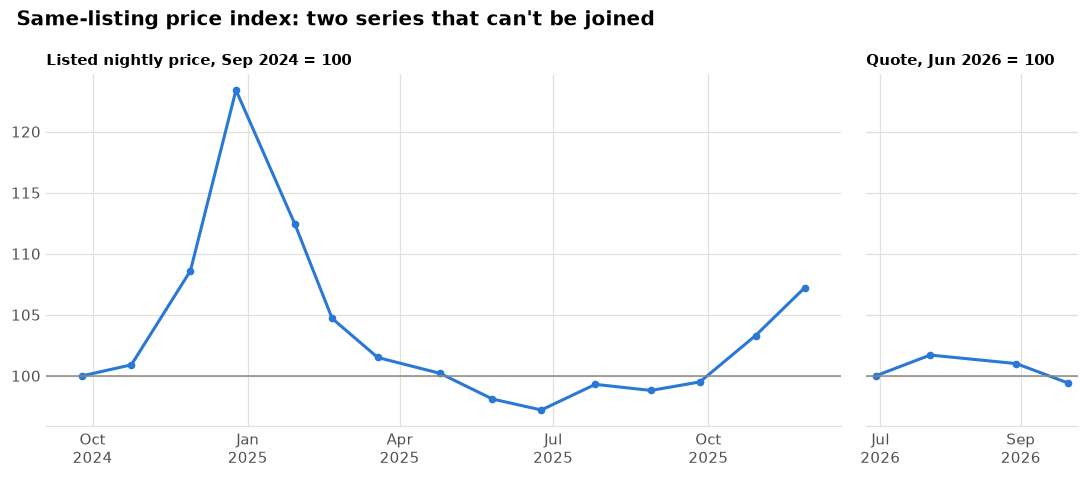

In [95]:
import matplotlib.dates
d = q("select * from trend_price_index")
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(10, 4.4), gridspec_kw={"width_ratios": [15, 4]})
for ax, basis, label in [(axes[0], "listed", "Listed nightly price, Sep 2024 = 100"),
                         (axes[1], "quote", "Quote, Jun 2026 = 100")]:
    x = d[d.price_basis == basis]
    ax.plot(x.snapshot_date, x.price_index, marker="o", ms=4, lw=2, color=BLUE)
    ax.axhline(100, color=MUTED, lw=1)
    ax.set_title(label, loc="left", fontsize=10, fontweight="bold")
    ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b\n%Y"))
axes[0].xaxis.set_major_locator(matplotlib.dates.MonthLocator(bymonth=(1, 4, 7, 10)))
axes[1].xaxis.set_major_locator(matplotlib.dates.MonthLocator(bymonth=(7, 9)))
fig.suptitle("Same-listing price index: two series that can't be joined", x=0.02, ha="left",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

In [96]:
q("select * from trend_price_index")

,snapshot_date,prev_date,price_basis,matched_listings,avg_change_pct,pct_unchanged,pct_up,pct_down,price_index
0,2024-09-25,NaT,listed,<NA>,NaN,NaN,NaN,NaN,100.0
1,2024-10-24,2024-09-25,listed,17216,0.89,52.9,28.7,18.4,100.9
2,2024-11-28,2024-10-24,listed,16967,7.59,45.0,47.3,7.7,108.6
3,2024-12-25,2024-11-28,listed,17436,13.67,39.3,52.0,8.7,123.4
4,2025-01-29,2024-12-25,listed,17639,-8.87,37.9,14.9,47.2,112.4
5,2025-02-20,2025-01-29,listed,18998,-6.85,22.6,16.2,61.3,104.7
6,2025-03-19,2025-02-20,listed,17187,-3.13,42.4,20.4,37.2,101.5
7,2025-04-25,2025-03-19,listed,18078,-1.24,37.4,27.7,34.9,100.2
8,2025-05-26,2025-04-25,listed,18924,-2.09,37.2,24.5,38.3,98.1
9,2025-06-24,2025-05-26,listed,19620,-0.90,33.7,34.9,31.4,97.2


In [97]:
q("select * from trend_district_growth")

,district,active_sep_2025,active_sep_2026,active_change,active_change_pct,all_listings_change_pct,growth_rank
0,Thon buri,194,322,128,66.0,65.0,1
1,Samphanthawong,149,200,51,34.2,20.8,2
2,Bang Na,355,463,108,30.4,11.6,3
3,Bang Kapi,214,265,51,23.8,39.8,4
4,Khlong San,386,473,87,22.5,9.9,5
5,Huai Khwang,1341,1586,245,18.3,19.6,6
6,Ratchathewi,854,1007,153,17.9,15.0,7
7,Phaya Thai,295,344,49,16.6,3.1,8
8,Pom Prap Sattru Phai,164,191,27,16.5,24.0,9
9,Vadhana,2585,2874,289,11.2,4.2,10


In [98]:
q("select * from trend_district_new_listings limit 10")

,district,active_change,newly_active,top_host_newly_active,top_host_pct
0,Thon buri,128,180.0,36,20.0
1,Samphanthawong,51,100.0,8,8.0
2,Bang Na,108,220.0,15,6.8
3,Bang Kapi,51,119.0,7,5.9
4,Khlong San,87,162.0,10,6.2
5,Huai Khwang,245,874.0,38,4.3
6,Ratchathewi,153,389.0,16,4.1
7,Phaya Thai,49,99.0,8,8.1
8,Pom Prap Sattru Phai,27,67.0,11,16.4
9,Vadhana,289,1072.0,49,4.6


In [99]:
q("select * from trend_cohort_retention")

,cohort_date,cohort_size,m3_pct,m6_pct,m12_pct,still_listed_sep_2026_pct
0,2024-10-24,1180,79.6,69.5,53.1,40.2
1,2024-11-28,1441,82.0,67.1,58.0,44.1
2,2024-12-25,1026,81.2,71.9,60.2,47.9
3,2025-01-29,1557,79.8,69.7,56.6,48.5
4,2025-02-20,959,74.1,60.4,NaN,41.0
5,2025-03-19,1461,77.7,67.6,NaN,48.9
6,2025-04-25,1262,82.2,75.0,NaN,51.0
7,2025-05-26,1027,81.6,74.3,NaN,53.6
8,2025-06-24,975,81.0,72.5,61.2,54.5
9,2025-07-26,1098,82.6,73.8,63.8,54.1


## 7. Stays under 30 nights

In [100]:
run("""
-- 07_short_stays.sql
-- Thailand's Hotel Act (2004) treats renting out a residential unit for less
-- than 30 days without a hotel licence as non-compliant. Two draft laws that
-- would change this were still drafts in January 2026:
-- https://www.nishimura.com/en/knowledge/publications/20260115-118456
--
-- The licence field in this dataset is empty for every Bangkok listing, so I
-- can't check who is licensed. What I can measure is how much of the supply
-- takes bookings under 30 nights. Some of that is legitimately licensed
-- (hotels, serviced apartments), so read these as exposure, not as a count of
-- illegal listings.
""")

In [101]:
run("""
-- 1. Stay length mix in the latest snapshot
create or replace view stay_mix as
select
    case
        when min_nights = 1  then '1 night'
        when min_nights < 7  then '2-6 nights'
        when min_nights < 30 then '7-29 nights'
        else '30+ nights'
    end                                                             as min_stay,
    count(*)                                                        as listings,
    round(100.0 * count(*) / sum(count(*)) over (), 1)              as pct_of_listings,
    count(*) filter (where is_active)                               as active_listings,
    round(100.0 * sum(est_revenue) / sum(sum(est_revenue)) over (), 1) as pct_of_revenue
from listing_occupancy
group by 1
order by min(min_nights);
""")

In [102]:
run("""
-- 2. By room type. Hotel rooms are the type most likely to hold a licence,
-- but the licence field is empty, so that can't be checked here.
create or replace view stay_by_room_type as
select
    room_type,
    count(*)                                                        as listings,
    round(100.0 * avg(case when min_nights < 30 then 1 else 0 end), 1) as pct_under_30_nights
from latest
group by room_type
order by listings desc;
""")

In [103]:
run("""
-- 3. Entire homes taking stays under 30 nights, by district
create or replace view stay_by_district as
select
    district,
    count(*)                                                        as entire_homes,
    count(*) filter (where min_nights < 30)                         as under_30_nights,
    round(100.0 * avg(case when min_nights < 30 then 1 else 0 end), 1) as pct_under_30_nights
from latest
where room_type = 'Entire home/apt'
group by district
having count(*) >= 100
order by pct_under_30_nights desc;
""")

In [104]:
run("""
-- 4. Over time. If enforcement or the law had moved, the monthly share should move.
create or replace view stay_trend as
select
    l.snapshot_date,
    s.is_complete,
    count(*)                                                        as listings,
    round(100.0 * avg(case when l.min_nights < 30 then 1 else 0 end), 1) as pct_under_30_nights,
    round(100.0 * avg(case when l.min_nights >= 30 then 1 else 0 end), 1) as pct_monthly_only
from stg_listings l
join snapshots s on s.snapshot_date = l.snapshot_date
where l.room_type = 'Entire home/apt'
group by l.snapshot_date, s.is_complete
order by l.snapshot_date;
""")

In [105]:
run("""
-- 5. Do the big operators behave differently from one-unit owners?
create or replace view stay_by_host_tier as
select
    case
        when h.listings = 1   then '1 listing'
        when h.listings <= 4  then '2-4'
        when h.listings <= 19 then '5-19'
        when h.listings <= 99 then '20-99'
        else '100+'
    end                                                             as host_tier,
    count(*)                                                        as entire_homes,
    round(100.0 * avg(case when l.min_nights < 30 then 1 else 0 end), 1) as pct_under_30_nights
from latest l
join host_latest h on h.host_id = l.host_id
where l.room_type = 'Entire home/apt'
group by 1
order by min(h.listings);
""")

In [106]:
q("select * from stay_mix")

,min_stay,listings,pct_of_listings,active_listings,pct_of_revenue
0,1 night,14343,46.4,7642,48.9
1,2-6 nights,6251,20.2,3916,23.2
2,7-29 nights,6002,19.4,3160,17.9
3,30+ nights,4326,14.0,1655,10.0


In [107]:
q("select * from stay_by_district")

,district,entire_homes,under_30_nights,pct_under_30_nights
0,Pom Prap Sattru Phai,127,126,99.2
1,Phra Nakhon,144,141,97.9
2,Samphanthawong,119,116,97.5
3,Suanluang,601,540,89.9
4,Bang Kapi,473,422,89.2
5,Yan na wa,315,280,88.9
6,Phasi Charoen,115,102,88.7
7,Bang Rak,662,585,88.4
8,Phaya Thai,318,280,88.1
9,Thon buri,416,358,86.1


In [108]:
q("select * from stay_trend")

,snapshot_date,is_complete,listings,pct_under_30_nights,pct_monthly_only
0,2024-09-25,True,15885,84.5,15.5
1,2024-10-24,True,16122,84.0,16.0
2,2024-11-28,True,16420,84.0,16.0
3,2024-12-25,True,16742,83.4,16.6
4,2025-01-29,True,17390,83.4,16.6
5,2025-02-20,True,17790,83.8,16.2
6,2025-03-19,True,18126,81.1,18.9
7,2025-04-25,True,18134,82.0,18.0
8,2025-05-26,True,18400,82.2,17.8
9,2025-06-24,True,18400,82.6,17.4


## Limits

- Occupancy is modelled from reviews. The 50% review rate is an assumption and the model caps at 70%.
- The calendar can't tell booked nights from blocked ones.
- Prices are what hosts ask, not what guests paid.
- Listing locations are shifted up to ~150 m by Airbnb, fine at district level.
- Licence data is empty for Bangkok, so the short-stay numbers are exposure, not a count of illegal listings.